# Week 6 Lab: From Flowchart to Code

**STISK2023 Programming for Data Science · DataFrames with pandas · CLO2 · CLO3**

You are the lab demonstrator for STISK2023. You have the quiz and lab marks of eight students, and the lecturer has eight questions about them. Each task gives you a **flowchart** of the logic. Your job is to **turn the flowchart into pandas code** by filling in the blanks `____`.

### How to work through each task

1. **Read the flowchart first.** Trace it from Start to End and say each step in plain words.
2. **Match the numbers.** Badge ① in the flowchart is the `# ①` line in the code cell.
3. **Fill in every `____`.** Each blank is one piece: a value, a column name, an operator or a method name.
4. **Run the code cell, then the Check cell below it.** Fix anything the check reports before you move on.
5. **Answer the Think question** in one or two sentences.

A cell that still contains `____` stops with an error. That is expected: fill in its blanks and run it again.

The tasks build on each other, so run the cells from top to bottom. If you get lost, use **Kernel → Restart Kernel and Run All Cells**.

| Part | Tasks | Time |
|---|---|---|
| Build and look | 1 Create and inspect · 2 Filter and sort · 3 Missing values | 20 min |
| New columns | 4 Calculated columns · 5 Grade bands with a function | 15 min |
| Combine and summarise | 6 Merge · 7 Group and summarise | 20 min |
| Challenge | 8 Flowchart only: you write all the code | 15 min or homework |

## How to read the flowcharts

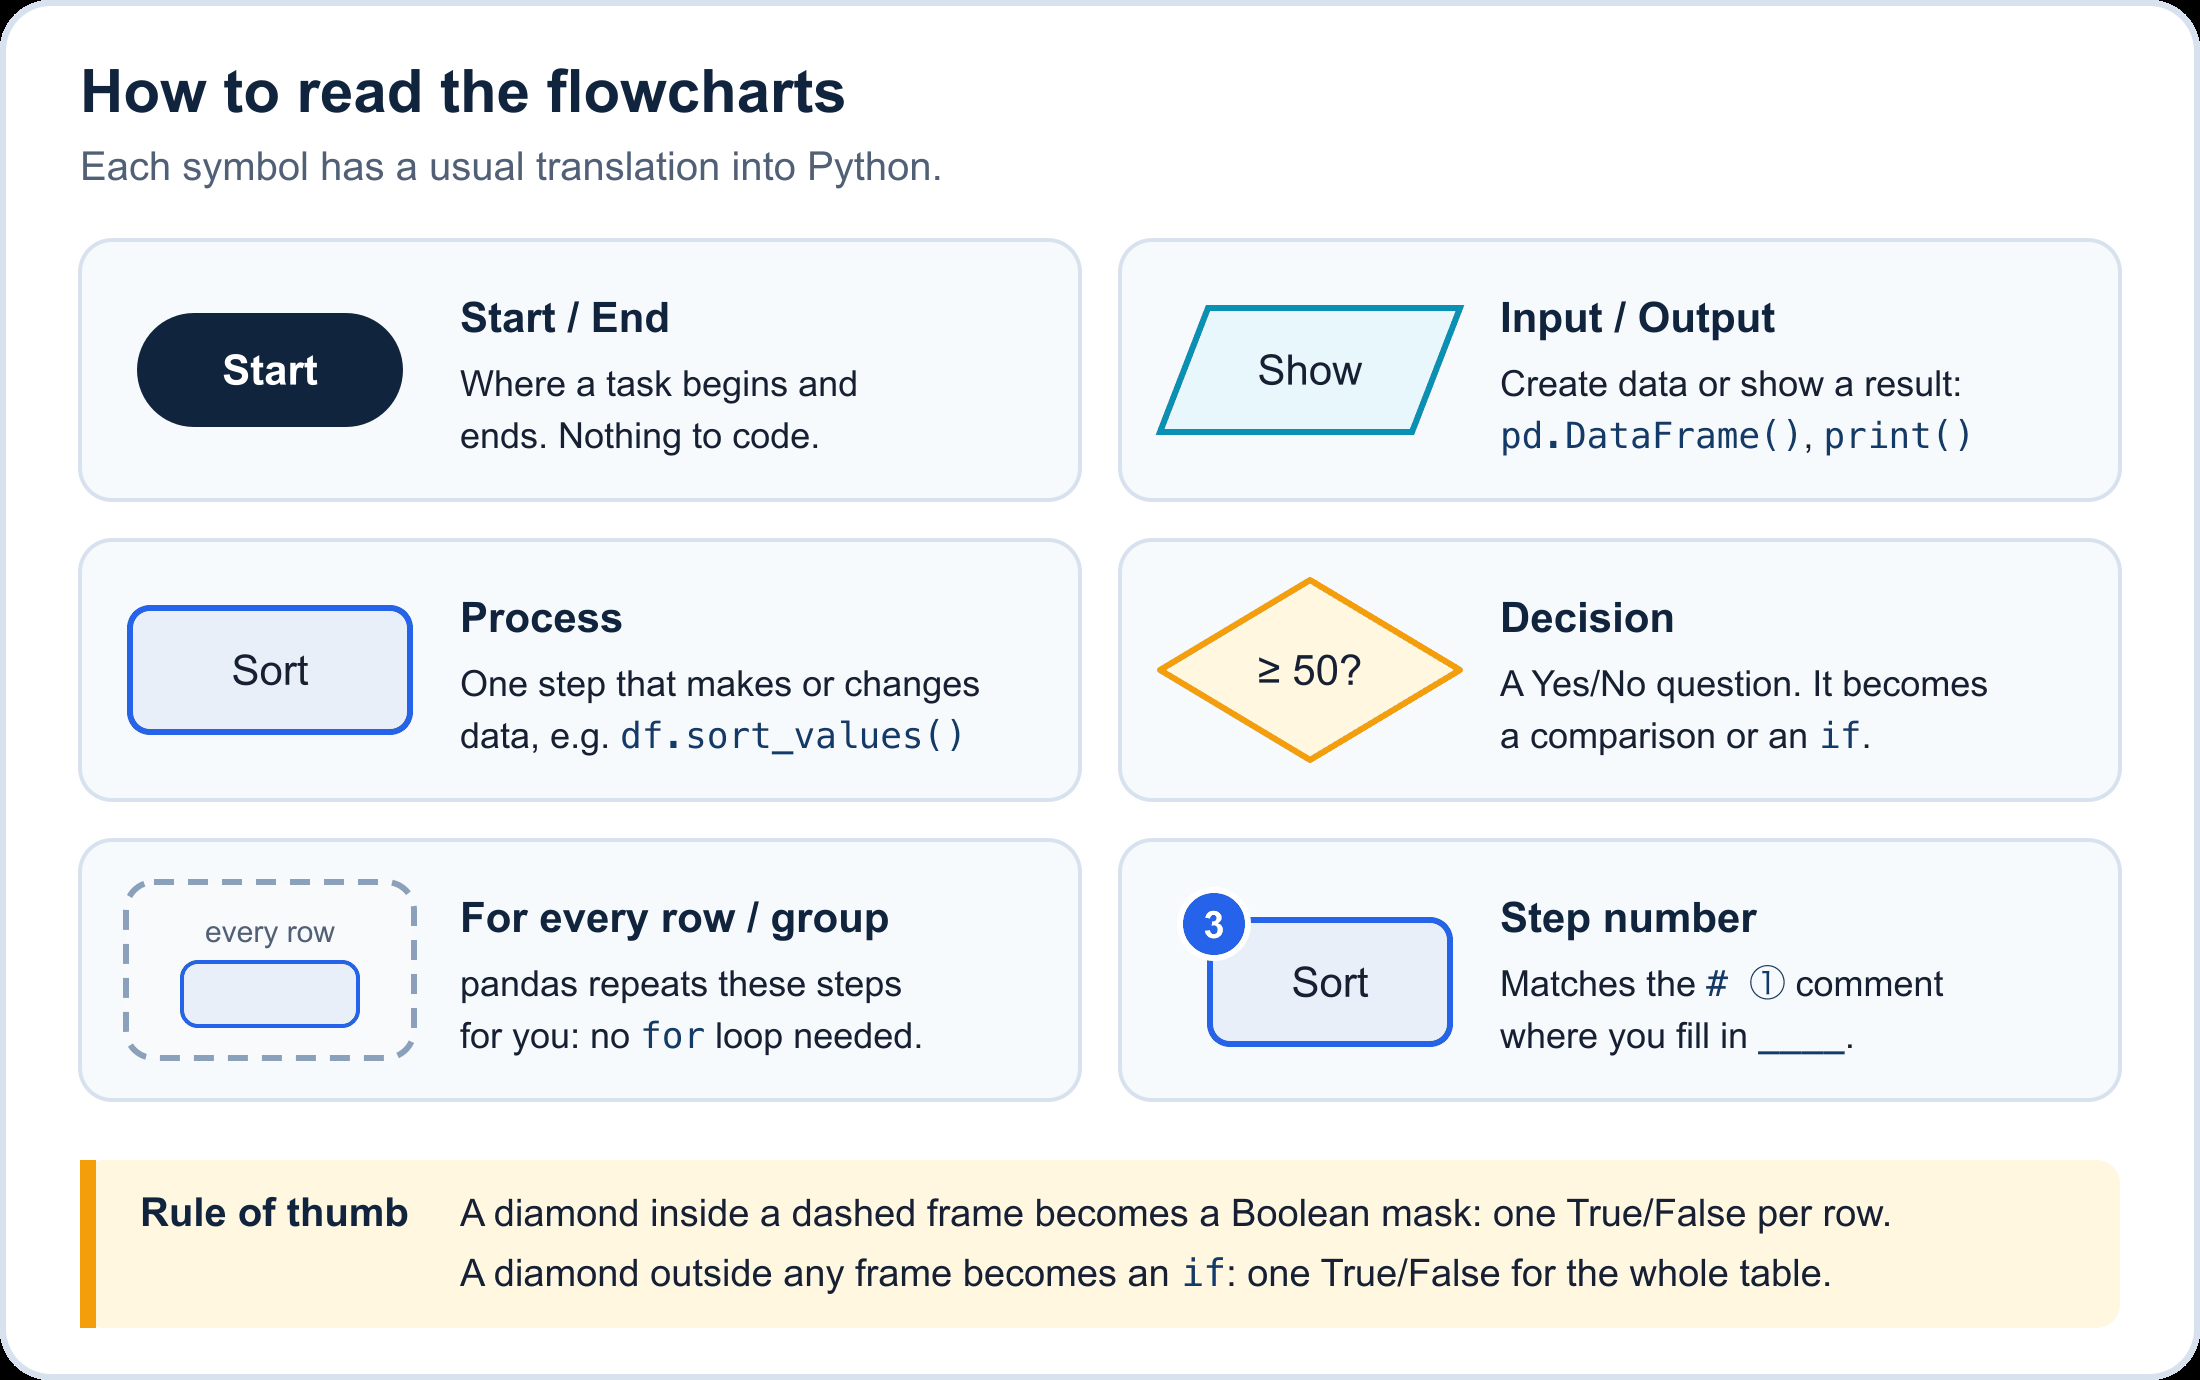

The rule of thumb at the bottom is the key idea of this lab. Watch for it in Tasks 2, 3 and 4.

## Your toolbox

Every blank uses one of these. All of them are on the Week 6 slides.

| Purpose | pandas |
|---|---|
| Make and look at a table | `pd.DataFrame({...})` · `.head(n)` · `.shape` · `.dtypes` |
| Pick rows and columns | `df.loc[rows, columns]` · `df[["a", "b"]]` · `&` means *and* |
| Order rows | `.sort_values(column, ascending=...)` |
| Missing values | `.isna()` · `.sum()` · `.count()` · `.mean()` · `.dropna(subset=[...])` · `.fillna(value)` |
| Use your own function | `.apply(function)` · `.value_counts()` |
| Combine tables | `.duplicated()` · `.merge(other, on=..., how=..., validate=...)` |
| Summarise groups | `.groupby(column, as_index=False).agg(new_name=(column, "size"))` with `"size"`, `"count"`, `"mean"` or `"sum"` |

In [1]:
import pandas as pd

print("pandas", pd.__version__)

pandas 2.3.3


---
## Task 1 · Create and inspect the table

**Question:** What does the marks table look like, and what type of data is in each column?

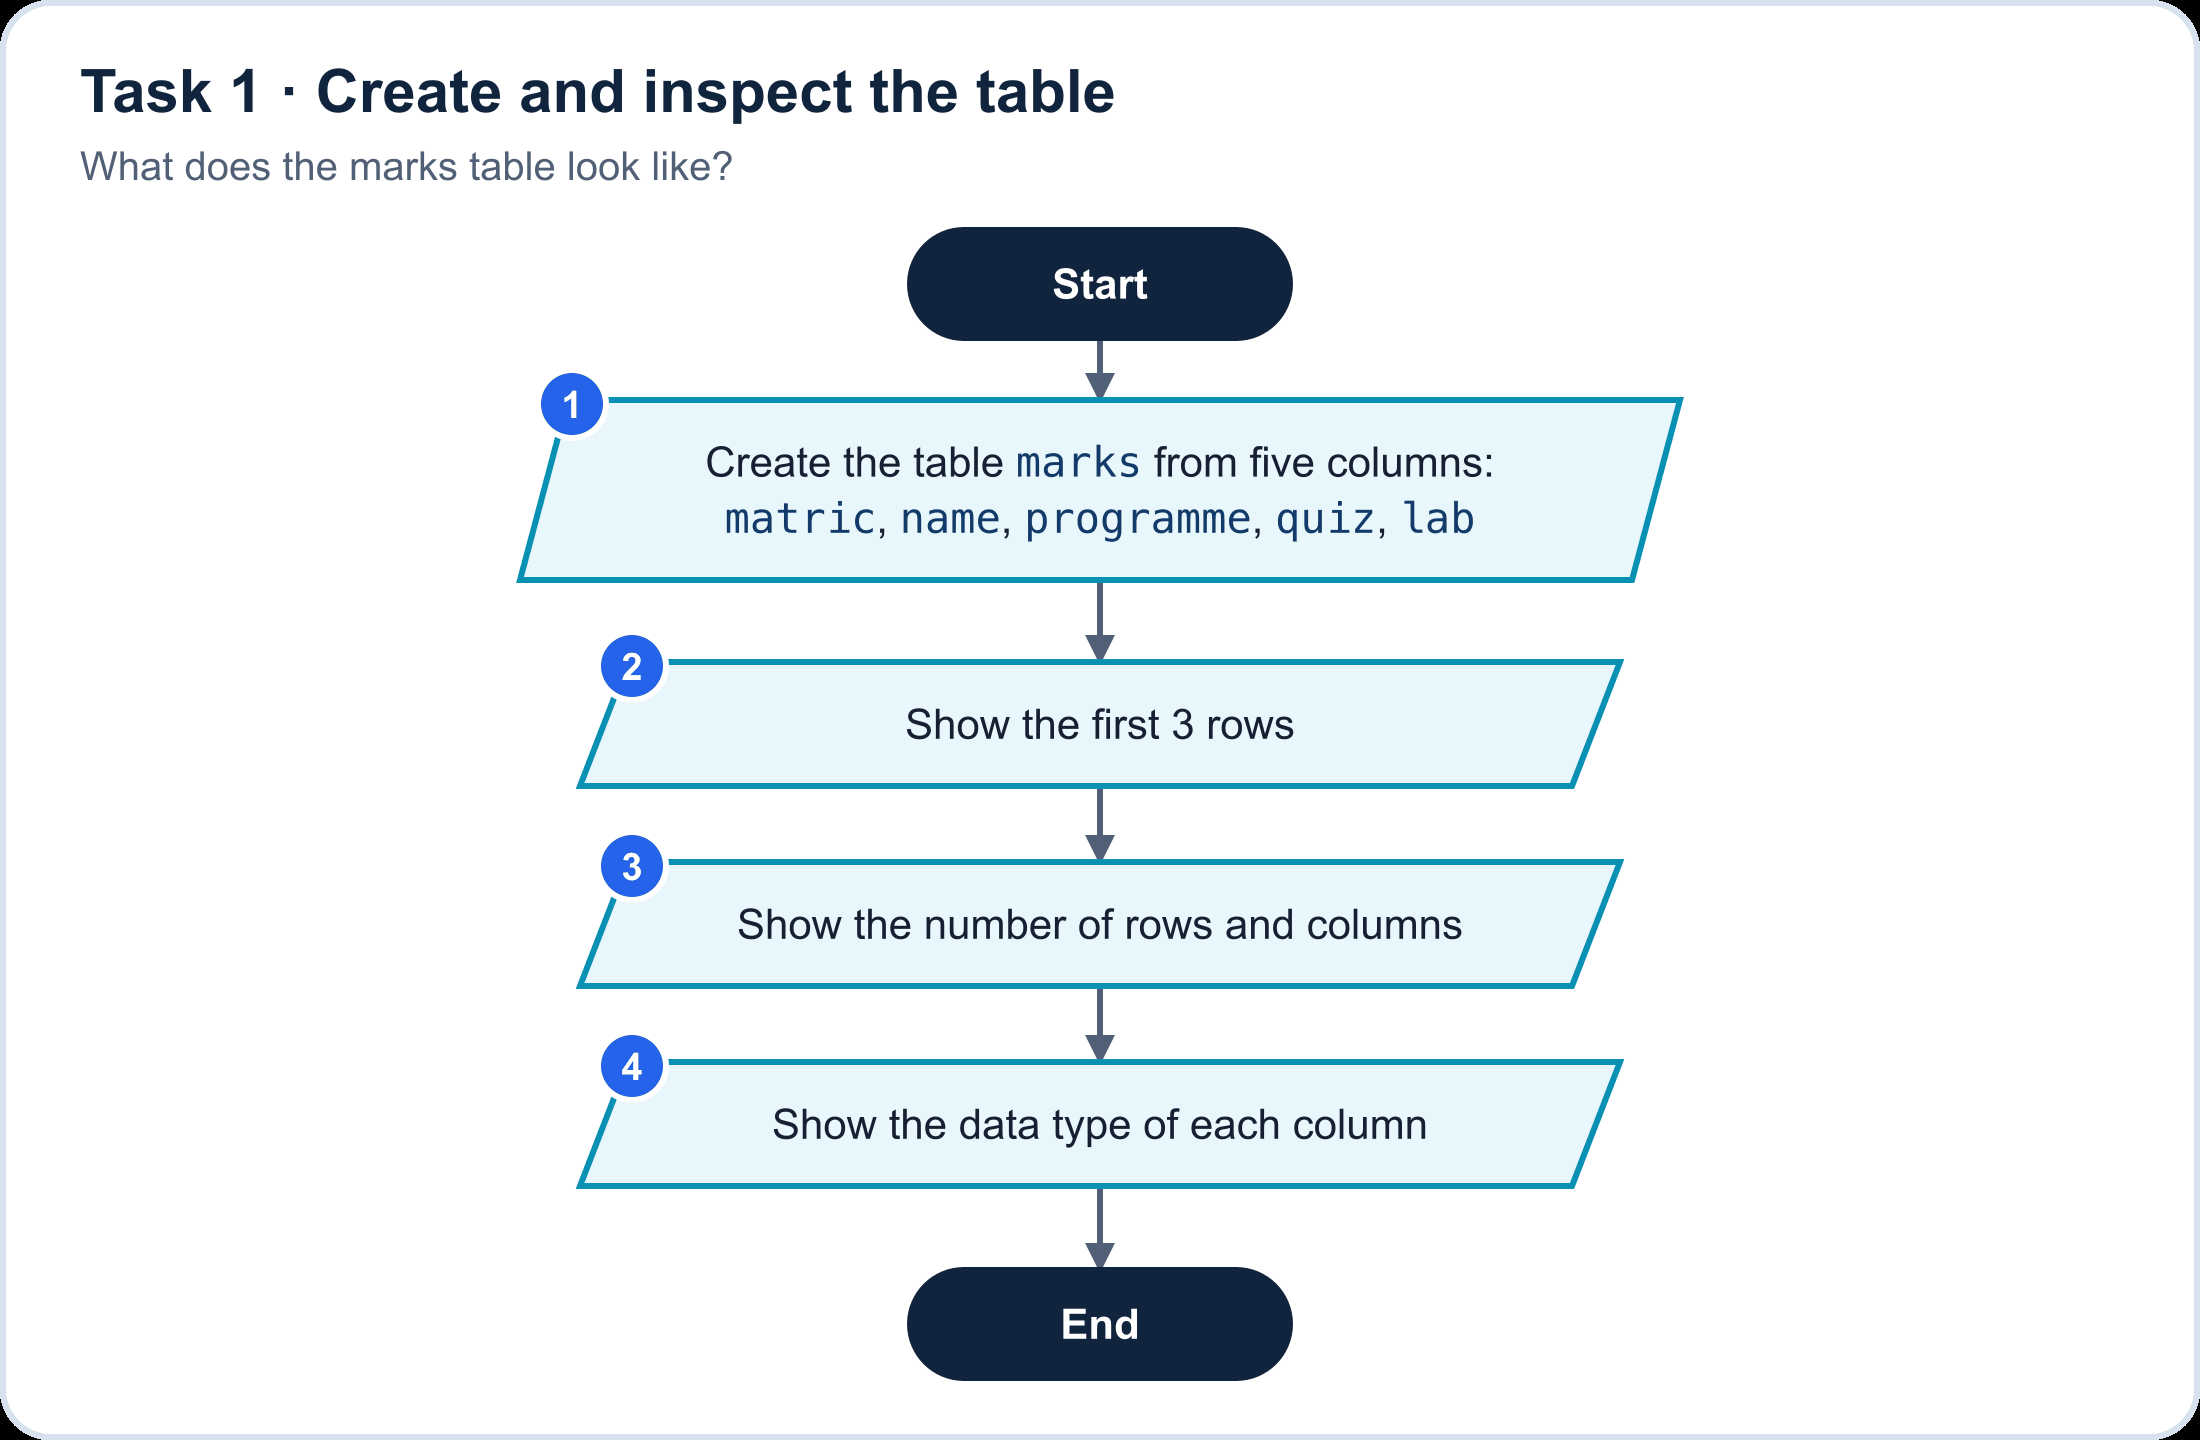

In [2]:
# ①
marks = pd.DataFrame({
    "matric":    ["S101", "S102", "S103", "S104", "S105", "S106", "S107", "S108"],
    "name":      ["Aina", "Ben", "Chong", "Devi", "Emir", "Farah", "Gopal", "Hana"],
    "programme": ["DS", "IT", "DS", "SE", "IT", "DS", "SE", "CS"],
    "quiz":      [16, 12, 18, None, 9, 8, 16, 13],  # out of 20 (Devi missed the quiz)
    "lab":       [24, 20, 28, 22, 16, 14, 25, 26],  # out of 30
})

# ②
print(marks.head(3))

# ③ An attribute, so no brackets
print(marks.shape)

# ④ Also an attribute
print(marks.dtypes)

  matric   name programme  quiz  lab
0   S101   Aina        DS  16.0   24
1   S102    Ben        IT  12.0   20
2   S103  Chong        DS  18.0   28
(8, 5)
matric        object
name          object
programme     object
quiz         float64
lab            int64
dtype: object


In [3]:
# Check: run this after the cell above
assert isinstance(marks, pd.DataFrame), "① marks should be a DataFrame"
assert marks.shape == (8, 5), "① marks should have 8 rows and 5 columns"
assert list(marks.columns) == ["matric", "name", "programme", "quiz", "lab"], "① keep the column names as given"
print("✅ Task 1 done")

✅ Task 1 done


**✍️ Think:** `quiz` is stored as `float64` but `lab` is `int64`, although both hold whole numbers. Why?

*Your answer: It contains a missing value (None). Pandas use a decimal capable data type to represent the missing value as NaN. The lab column is stored as int64 because it contains only whole numbers and has no missing values. 

---
## Task 2 · Filter rows, pick columns, sort

**Question:** Which DS students scored at least 24 in the lab? Show only their name and lab mark, best first.

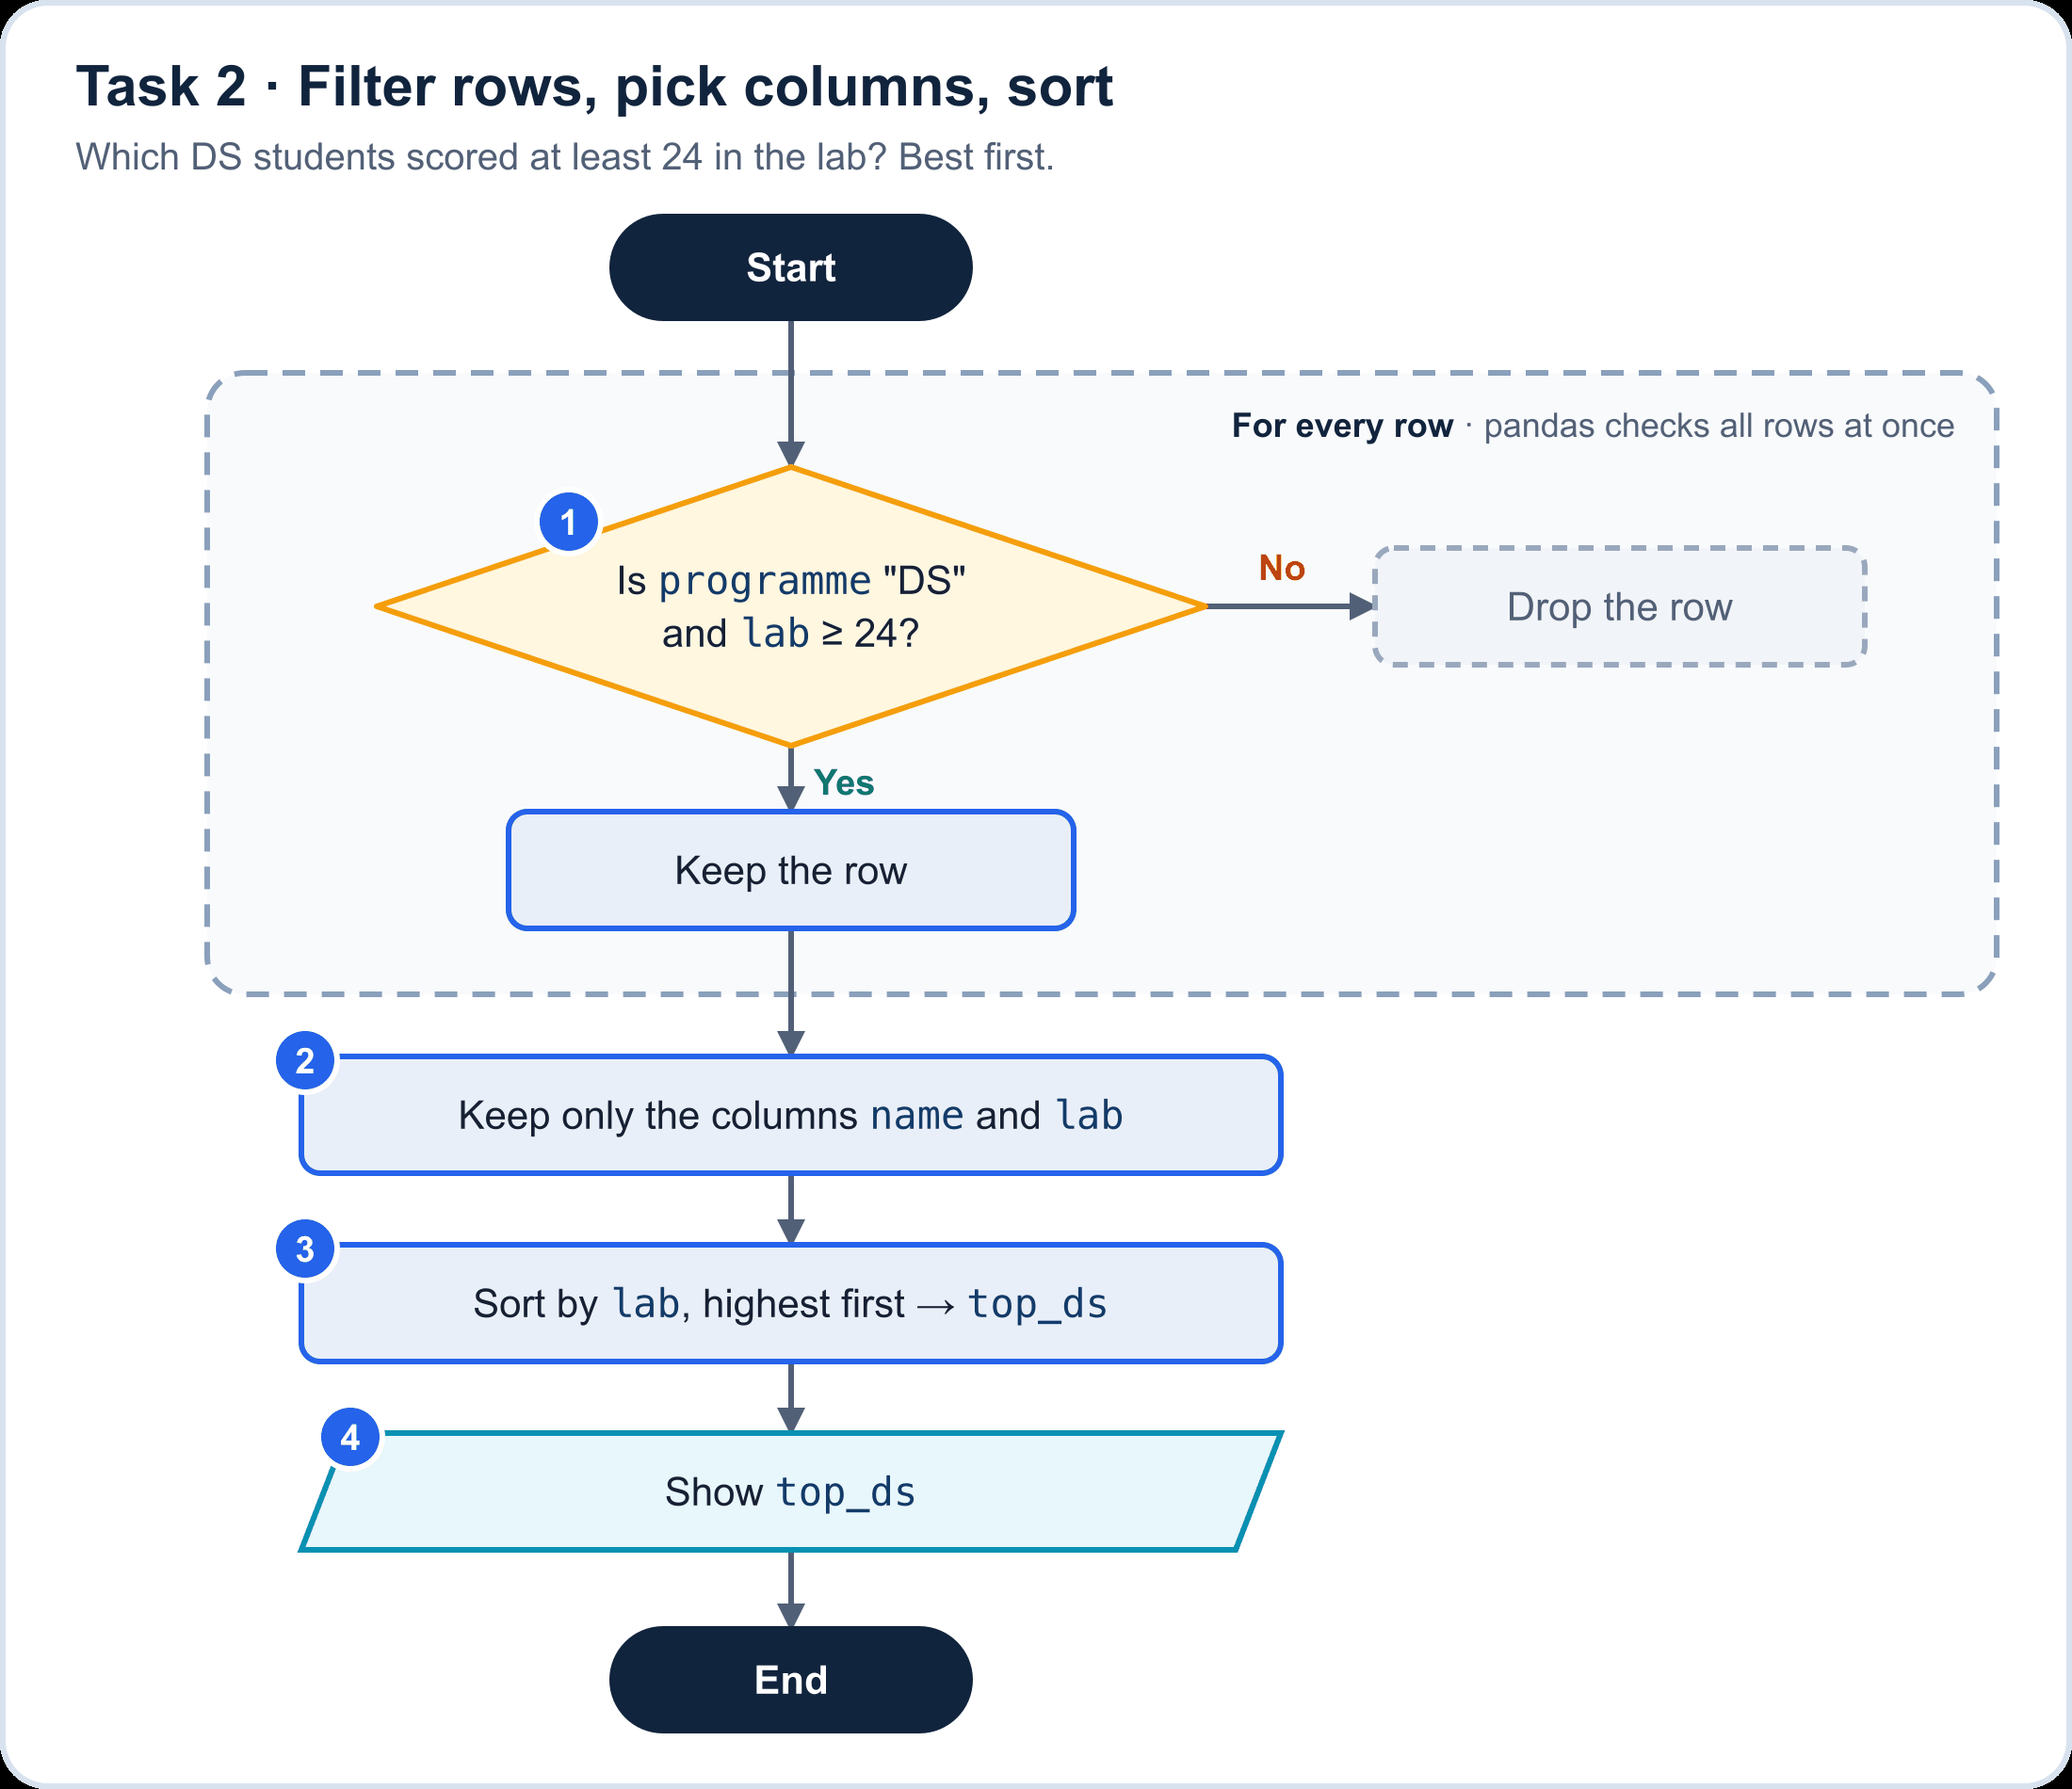

In [4]:
# ① The question is asked of every row, so it becomes Boolean masks
is_ds = marks["programme"] == "DS"
good_lab = marks["lab"] >= 24

# ① + ② Keep the rows where both masks are True, and only two columns
top_ds = marks.loc[is_ds & good_lab, ["name", "lab"]]

# ③
top_ds = top_ds.sort_values("lab", ascending=False)

# ④
print(top_ds)

    name  lab
2  Chong   28
0   Aina   24


In [5]:
# Check: run this after the cell above
assert list(top_ds.columns) == ["name", "lab"], "② keep only the name and lab columns, in that order"
assert top_ds["name"].tolist() == ["Chong", "Aina"], "① or ③ expected Chong, then Aina. Is 24 itself allowed? Which way is the sort?"
print("✅ Task 2 done")

✅ Task 2 done


**✍️ Think:** The printed row labels are `2` and `0`, not `0` and `1`. Why? What would `top_ds.loc[0]` return?

*Your answer: The row labels remain 2 and 0 because filtering and sorting do not automatically reset the original index. top_ds.loc[0] would return Aina's row because its original row label is 0.

---
## Task 3 · Missing values

**Question:** What is the class's average quiz mark, and how many students is it based on?

![Task 3 flowchart: Start; 1 count the missing quiz marks, giving n_missing; 2 decision asked once about the whole table: is n_missing greater than 0? Yes 3 show the names of the students with no quiz mark; No show No missing quiz marks; 4 average and count the recorded quiz marks; 5 report the mean and how many students it is based on; End.](attachment:task3.png)
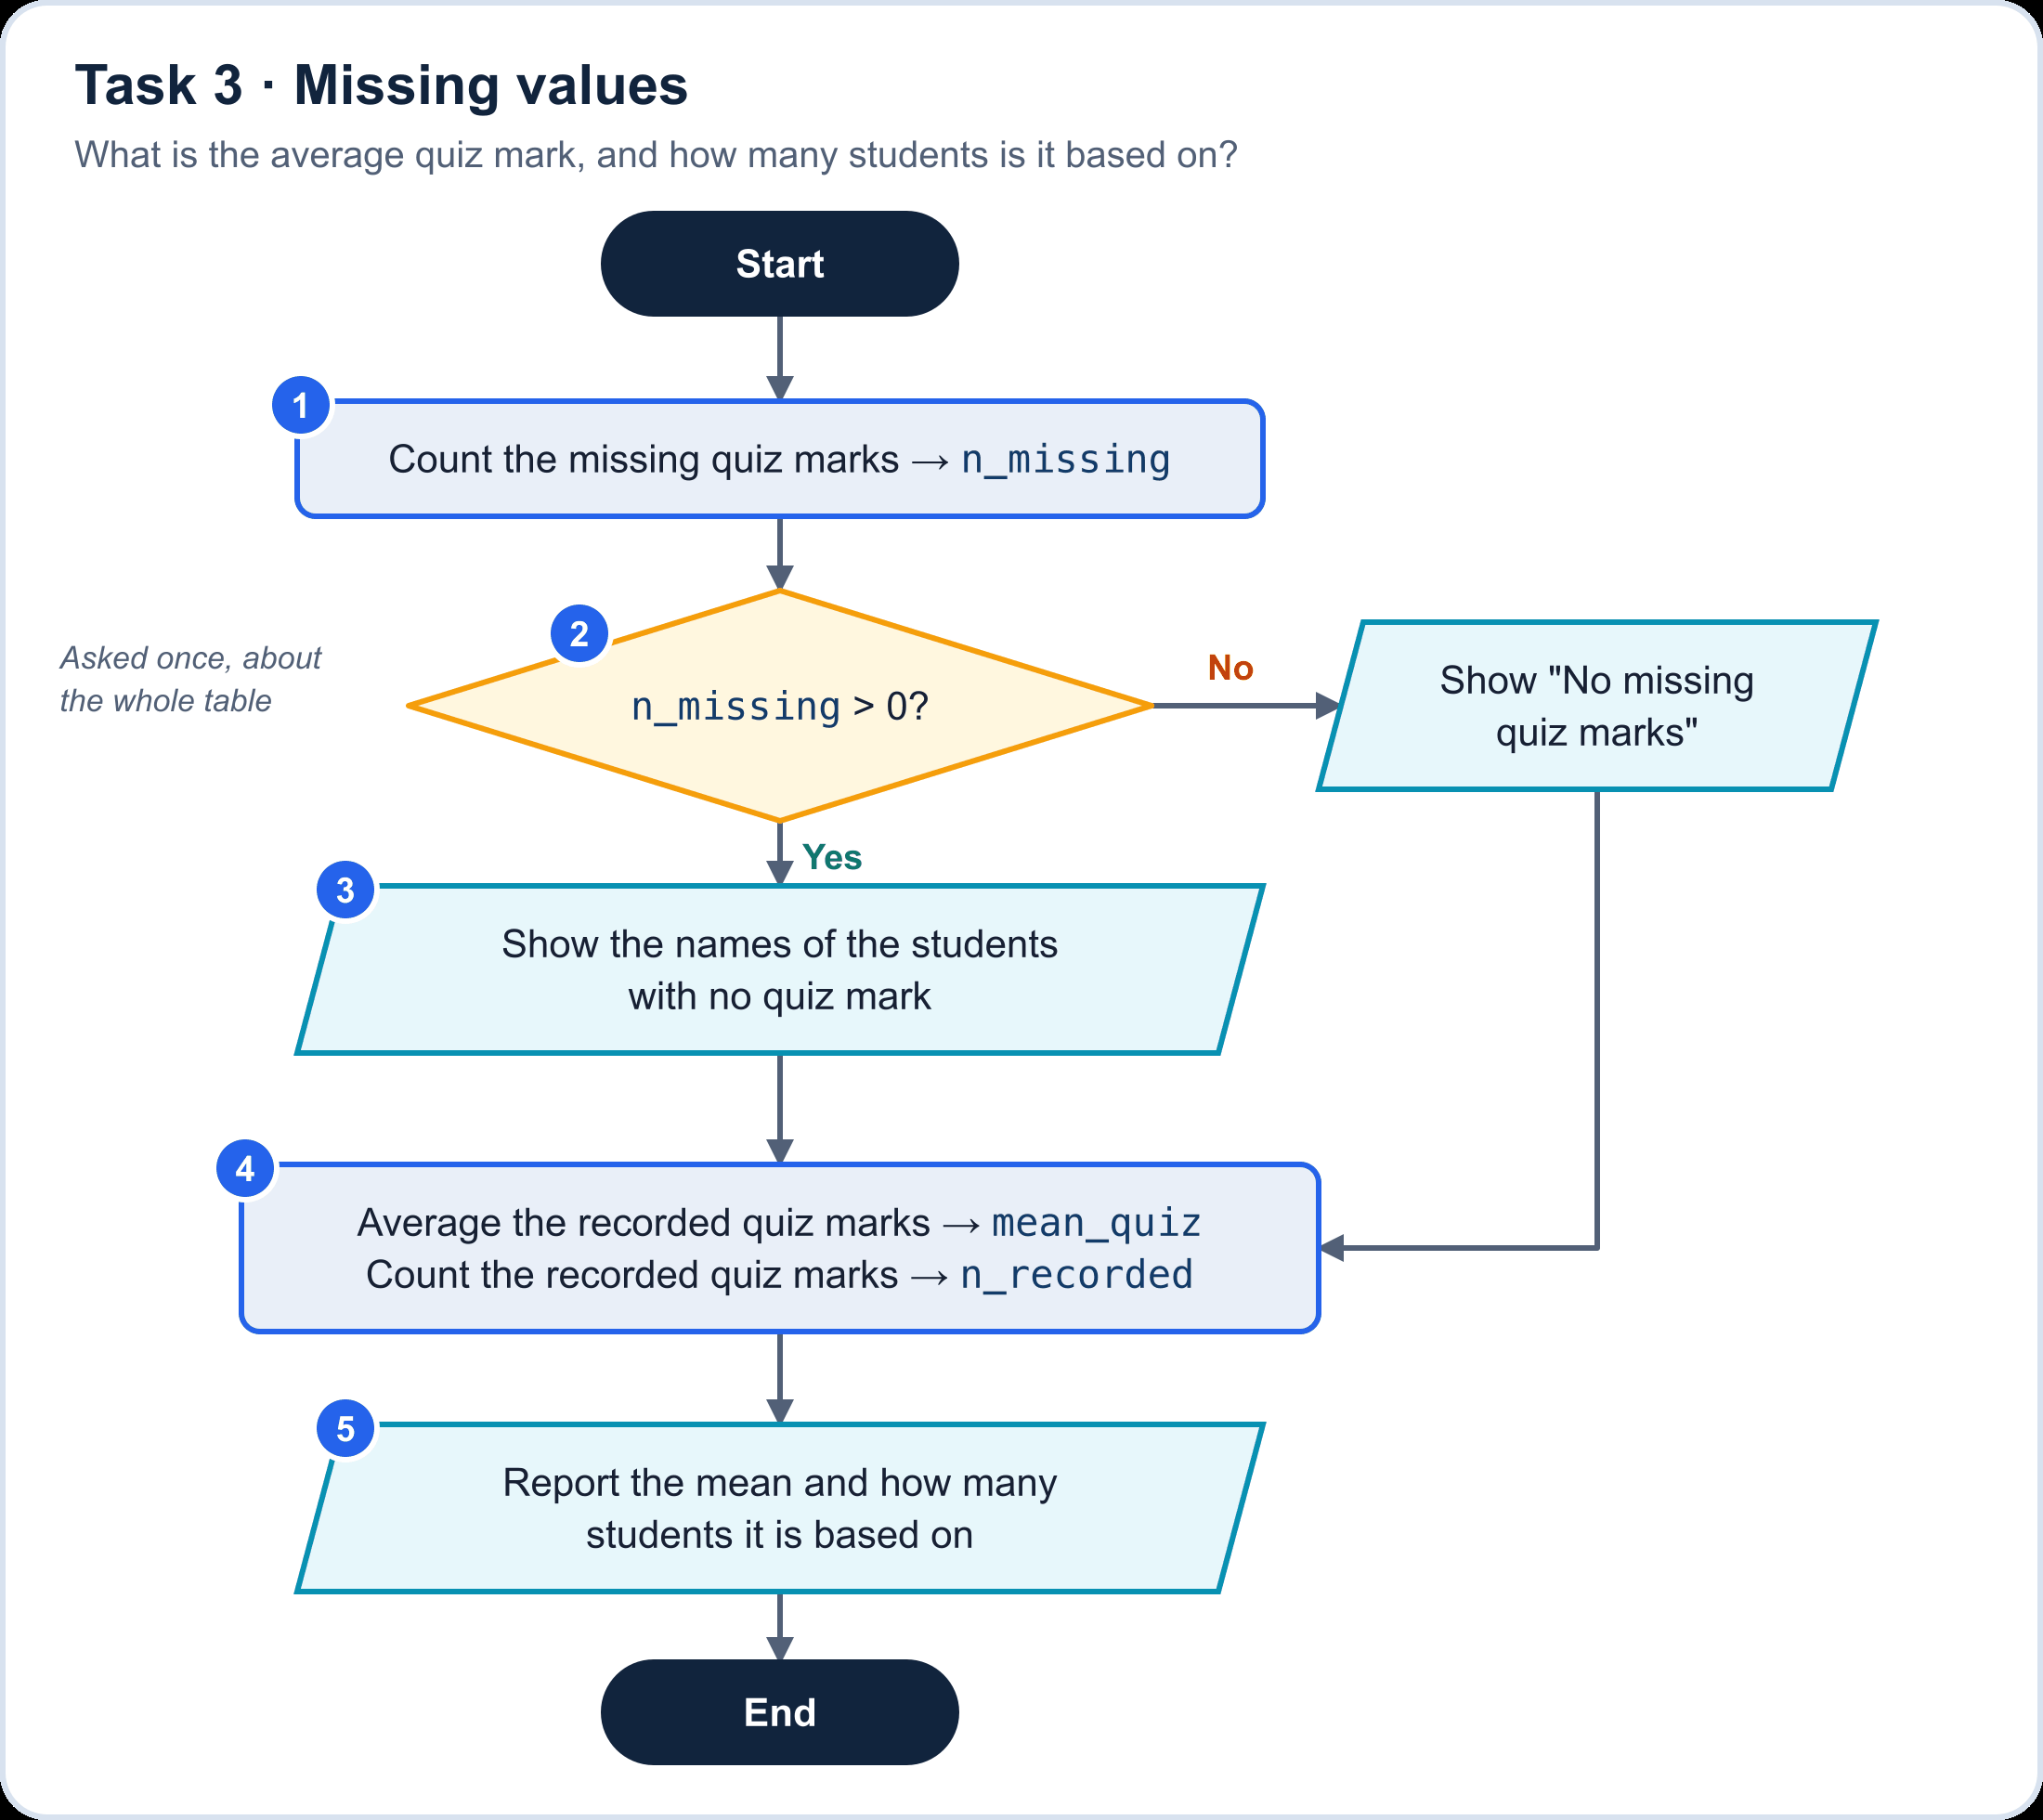

In [6]:
# ①
n_missing = marks["quiz"].isna().sum()

# ② One question about the whole table, so an ordinary if
if n_missing > 0:
    # ③ One column name gives a Series of names
    missing_names = marks.loc[marks["quiz"].isna(), "name"]
    print("No quiz mark:", missing_names.tolist())
else:
    print("No missing quiz marks")

# ④ .mean() and .count() skip missing values
mean_quiz = marks["quiz"].mean()
n_recorded = marks["quiz"].count()

# ⑤
print(f"Mean quiz mark: {mean_quiz:.2f} (from {n_recorded} of {len(marks)} students)")

No quiz mark: ['Devi']
Mean quiz mark: 13.14 (from 7 of 8 students)


In [7]:
# Check: run this after the cell above
assert n_missing == 1, "① n_missing should be 1: mark each missing value, then add up the True values"
assert missing_names.tolist() == ["Devi"], "③ select the name column for the rows where quiz is missing"
assert n_recorded == 7, "④ count only the recorded quiz marks"
assert round(mean_quiz, 2) == 13.14, "④ take the mean of the quiz column"
print("✅ Task 3 done")

✅ Task 3 done


**✍️ Think:** 1. `marks["quiz"].fillna(0).mean()` gives `11.50`. Which number would you report to the lecturer, and how would you word it?

2. Task 2's diamond became a Boolean mask, but this task's diamond became an `if`. Look at the two flowcharts: what is the difference?

*Your answer: 
1. I would report 13.14, based on the 7 students who have recorded quiz marks. I would explain that one student's quiz mark is missing, so the average is calculated using only the 7 available marks. I would not use 11.50 because treating the missing mark as zero would unfairly lower the 
average.

2. Task 2's diamond checks a condition for each row, producing a Boolean mask (True or False) for each student. Task 3's diamond checks one condition for the whole dataset, so it uses an if statement to decide which action to perform.


---
## Task 4 · Calculated columns

**Question:** What is each student's coursework percentage, and did they pass (50% or more)?

![Task 4 flowchart: Start; inside a frame for every row, 1 coursework equals quiz plus lab, out of 50; 2 coursework_pct equals coursework divided by 50 times 100; 3 decision: is coursework_pct at least 50? Yes passed is True, No passed is False; 4 show name, coursework_pct and passed; End.](attachment:task4.png)
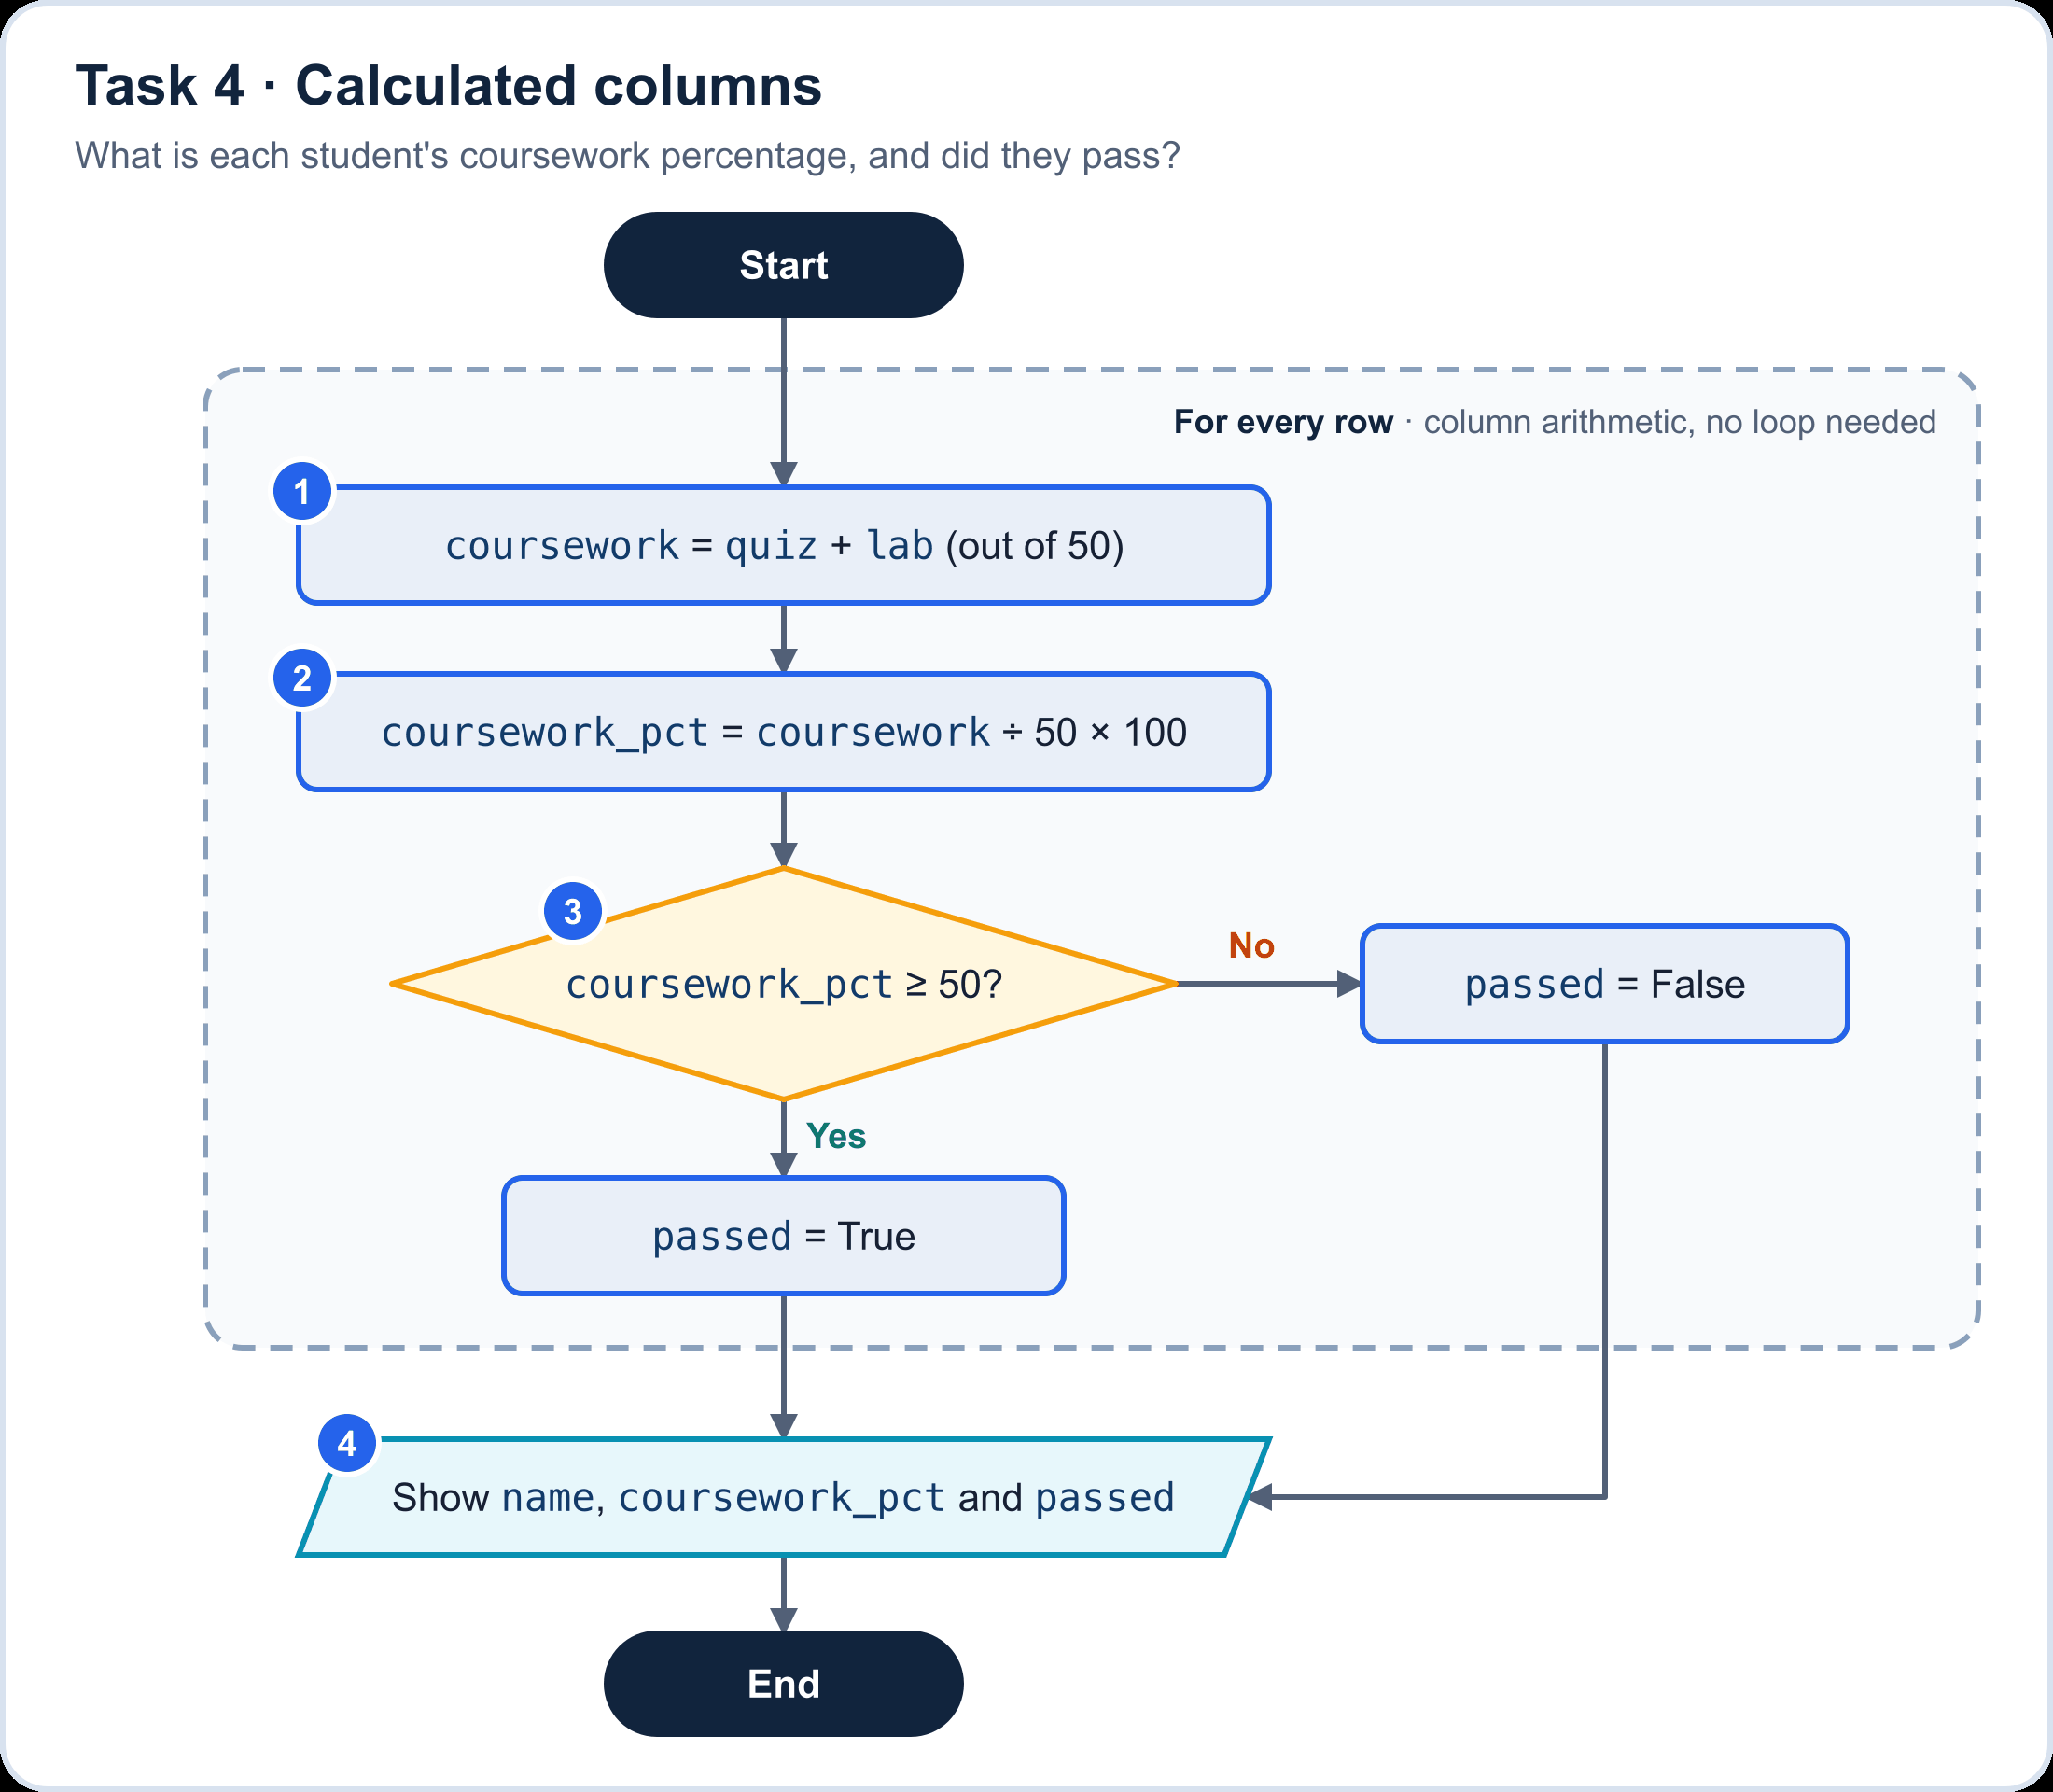

In [8]:
# ① ② Column arithmetic runs once for every row: no loop needed
marks["coursework"] = marks["quiz"] + marks["lab"]
marks["coursework_pct"] = marks["coursework"] / 50 * 100

# ③ A Yes/No decision whose answers are True/False is just a comparison
marks["passed"] = marks["coursework_pct"] >= 50

# ④
print(marks[["name", "coursework_pct", "passed"]])

    name  coursework_pct  passed
0   Aina            80.0    True
1    Ben            64.0    True
2  Chong            92.0    True
3   Devi             NaN   False
4   Emir            50.0    True
5  Farah            44.0   False
6  Gopal            82.0    True
7   Hana            78.0    True


In [9]:
# Check: run this after the cell above
assert marks["coursework_pct"].dropna().round(1).tolist() == [80.0, 64.0, 92.0, 50.0, 44.0, 82.0, 78.0], "①② coursework_pct is (quiz + lab) ÷ 50 × 100"
assert marks["passed"].sum() == 6, "③ passed should be True for 50 or more. Look at Emir"
print("✅ Task 4 done")

✅ Task 4 done


**✍️ Think:** Devi's `passed` is `False`, but she has not failed: her quiz mark is missing. Why does pandas say `False`?

*Your answer: Pandas treats the missing quiz mark as NaN. When it calculates Devi's coursework percentage, the result is also missng. Comparing a missing value with 50 using >= returns False, but this does not mean Devi failed. Her actual result is unknown because her quiz mark is missing. 

---
## Task 5 · Grade bands with your own function

**Question:** Which grade band is each student in? Missing coursework is *Incomplete*, not a fail.

![Task 5 flowchart. Function grade_band(pct): 1 is pct missing? Yes return Incomplete; 2 is pct at least 80? Yes return A; 3 is pct at least 65? Yes return B; 4 is pct at least 50? Yes return C; otherwise return F. Main program: Start; 5 for every value, call grade_band on coursework_pct, giving the column grade; 6 count the students in each grade; End.](attachment:task5.png)
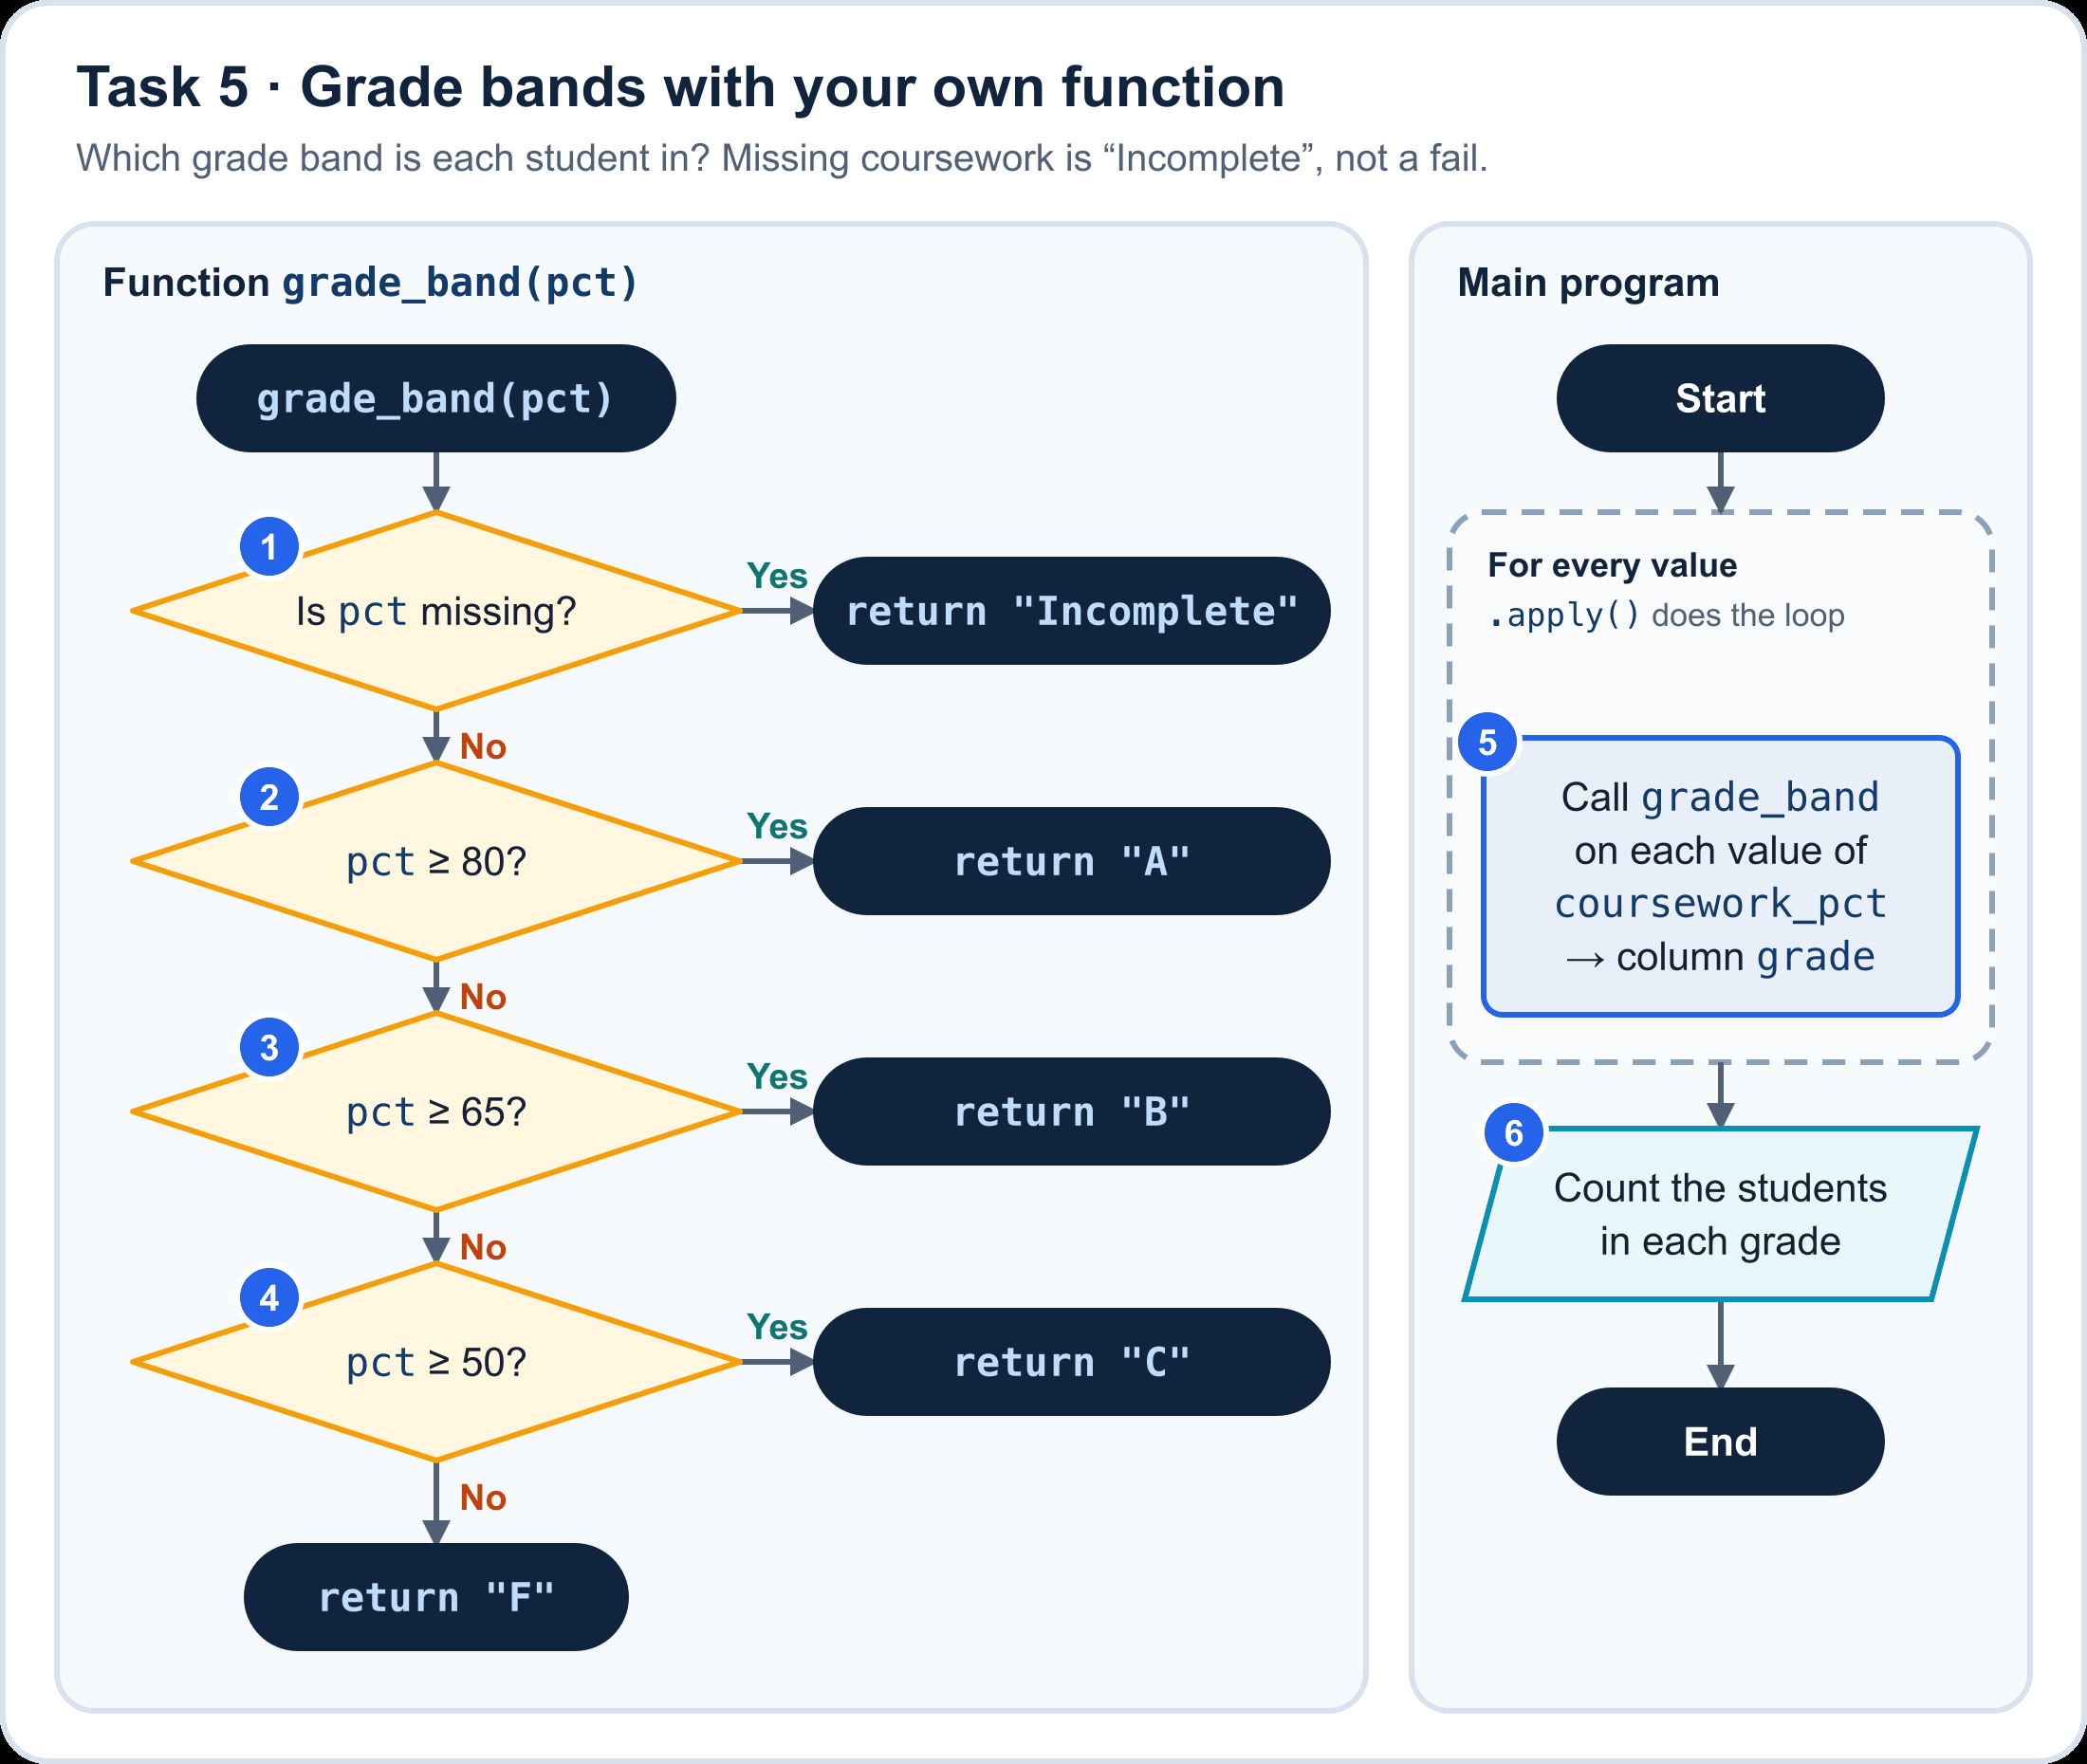

In [10]:
# ① – ④ A chain of decisions becomes if / elif / else
def grade_band(pct):
    if pd.isna(pct):   # ①
        return "Incomplete"
    elif pct >= 80:  # ②
        return "A"
    elif pct >= 65:         # ③
        return "B"
    elif pct >= 50:    # ④
        return "C"
    else:
        return "F"

# ⑤ Pass the function itself: no brackets after its name
marks["grade"] = marks["coursework_pct"].apply(grade_band)

# ⑥
print(marks["grade"].value_counts())

grade
A             3
C             2
Incomplete    1
F             1
B             1
Name: count, dtype: int64


In [11]:
# Check: run this after the cell above
assert grade_band(80) == "A" and grade_band(79.9) == "B", "② 80 itself should be an A"
assert grade_band(65) == "B" and grade_band(64.9) == "C", "③ 65 itself should be a B"
assert grade_band(50) == "C" and grade_band(49.9) == "F", "④ 50 itself should be a C"
assert grade_band(float("nan")) == "Incomplete", "① a missing value should be Incomplete"
assert marks["grade"].tolist() == ["A", "C", "A", "Incomplete", "C", "F", "A", "B"], "⑤ apply grade_band to coursework_pct"
print("✅ Task 5 done")

✅ Task 5 done


**✍️ Think:** Why must *Is pct missing?* be the first decision, and why must `≥ 80` be checked before `≥ 65`?

*Your answer: The missing value must be checked first so that students with missing marks are labelled "Incomplete" instead of being given a fail grade. The condition >= 80 must be checked before >= 65 because students scoring 80 or above also meet the condition >= 65. Checking the higher grade first ensures they receive grade A. 

---
## Task 6 · Merge with key checks

**Question:** Add each student's full programme name without losing or duplicating anyone.

![Task 6 flowchart: Start; 1 decision: is any programme code repeated in programmes? Yes stop and fix the lookup table; No 2 left-join programmes onto marks using programme, many students to one programme, giving enriched; 3 decision: does enriched have the same number of rows as marks? No stop; Yes 4 find the students with no programme name, giving unmatched; 5 show unmatched; End.](attachment:task6.png)
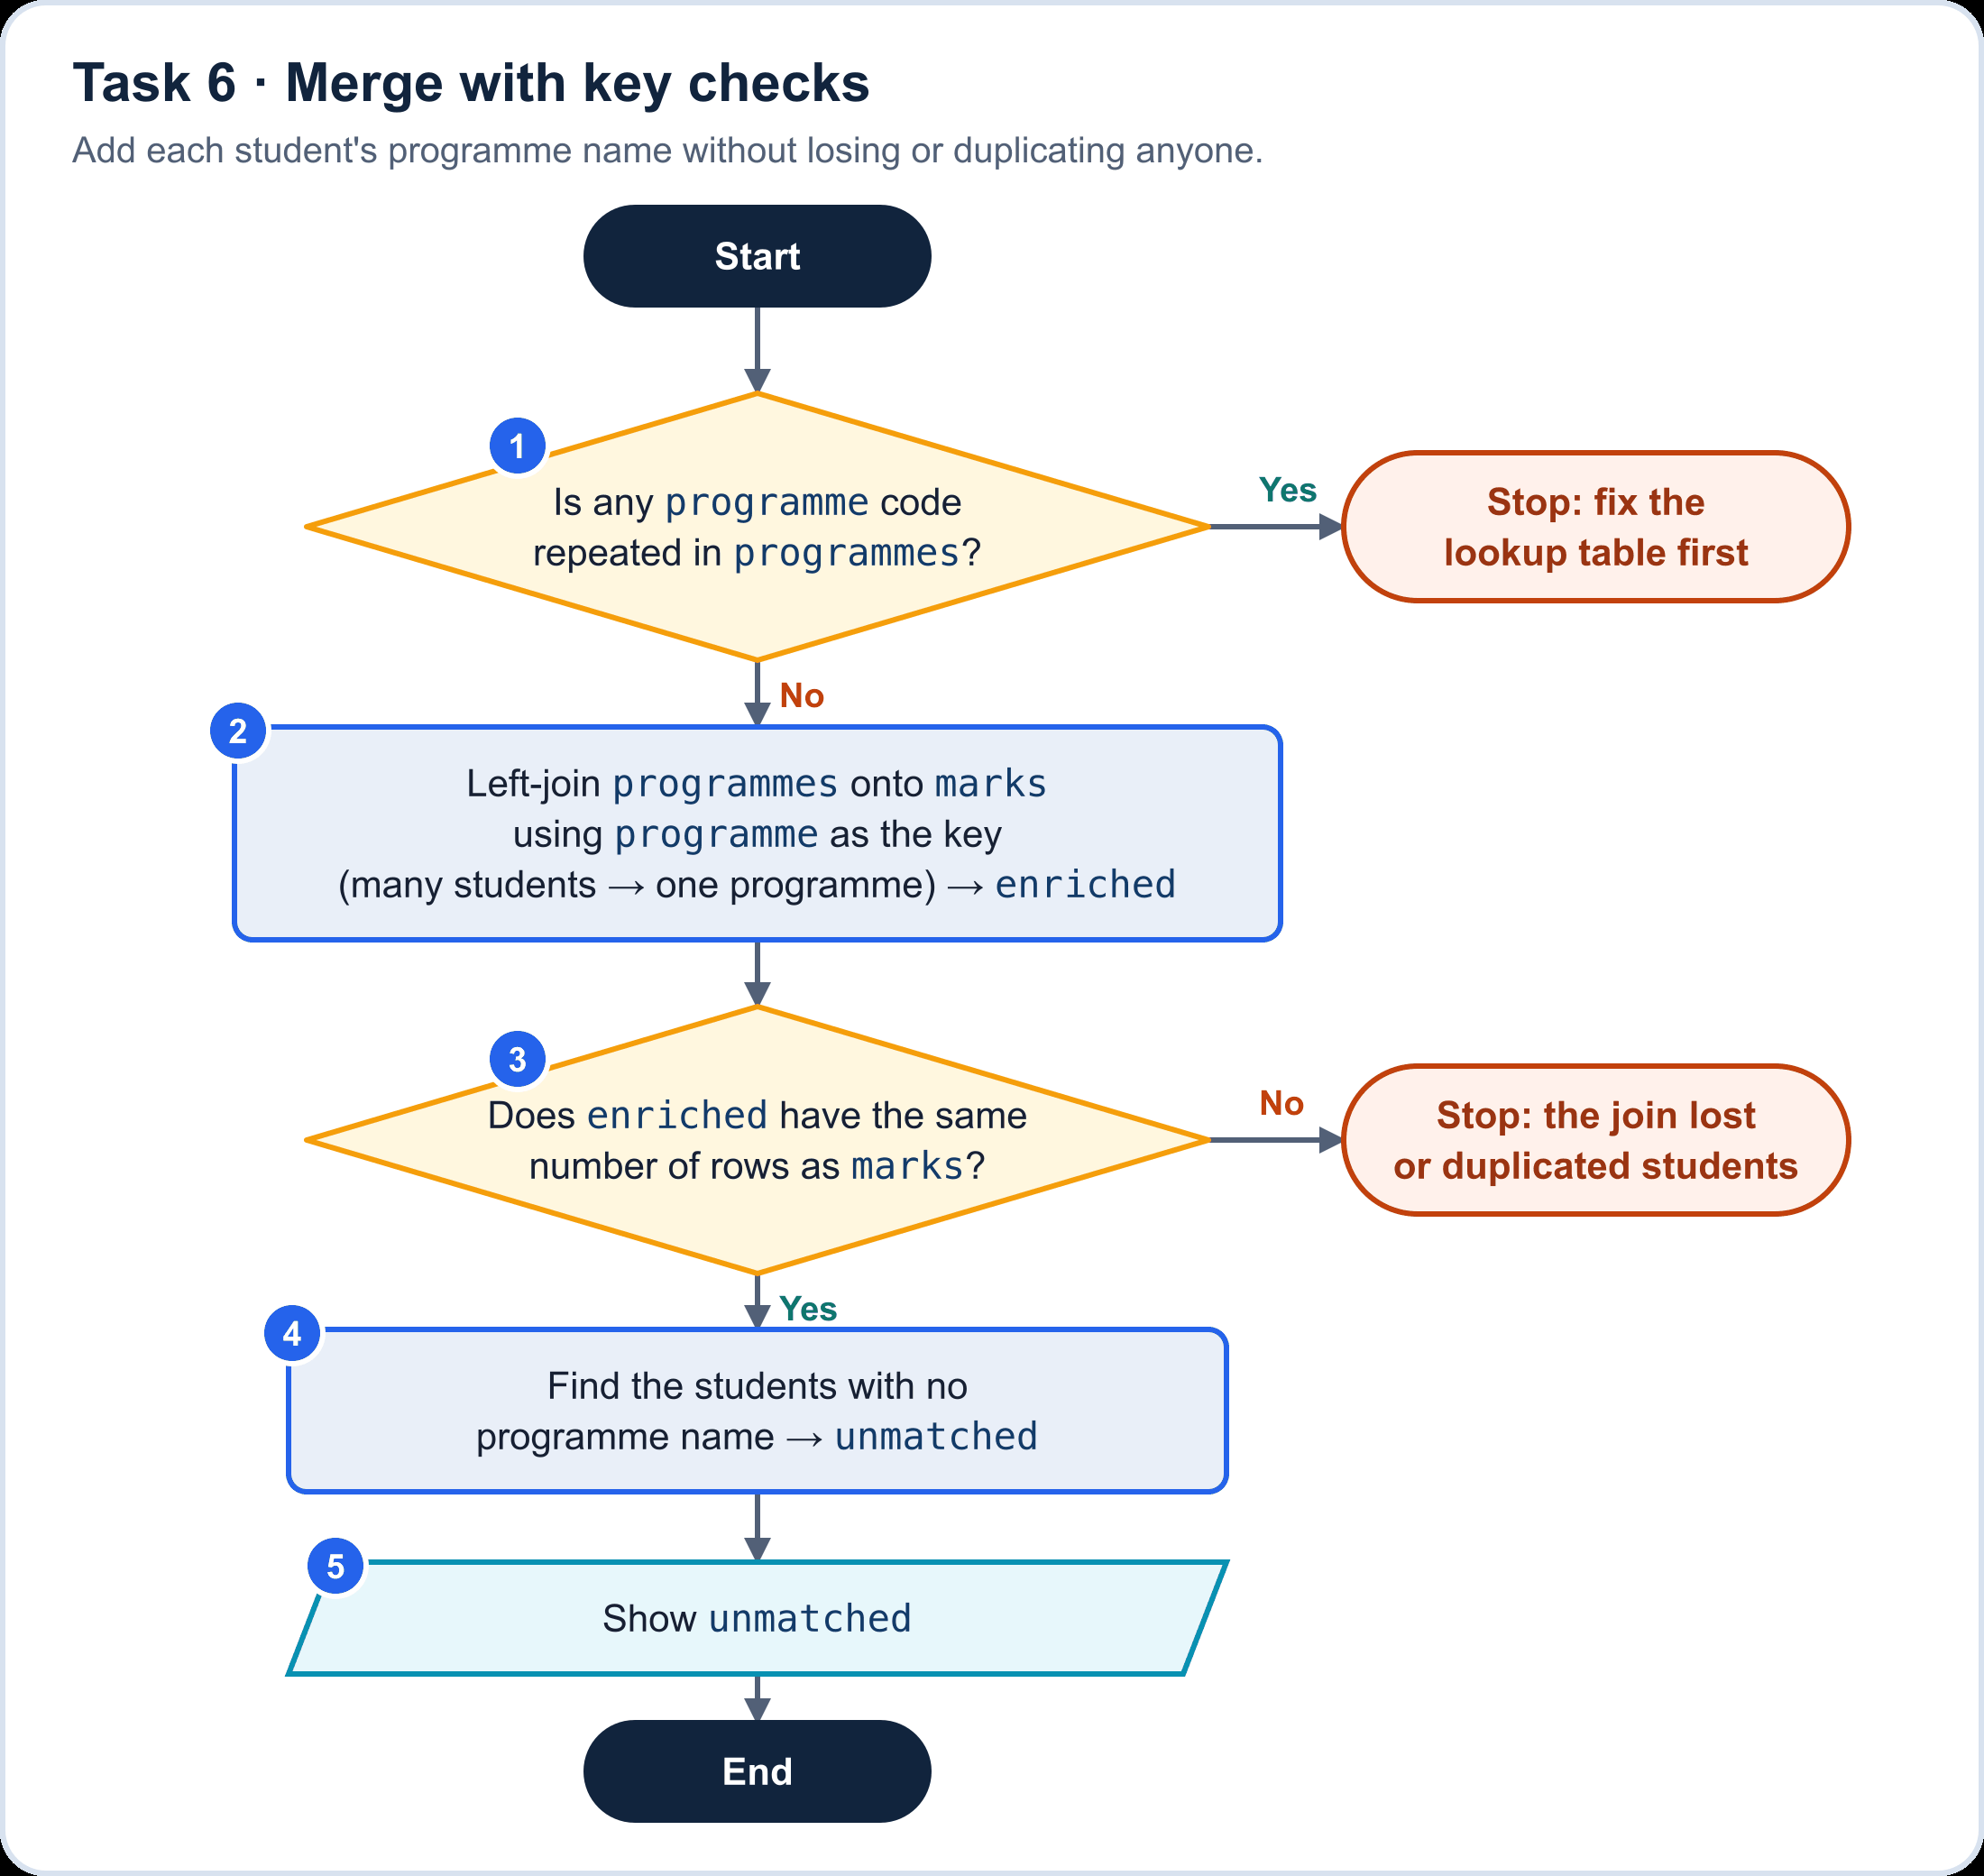

In [12]:
programmes = pd.DataFrame({
    "programme": ["DS", "IT", "SE"],
    "programme_name": ["Data Science", "Information Technology", "Software Engineering"],
})

# ① One question about the whole lookup table, so an ordinary if
if programmes["programme"].duplicated().any():
    raise ValueError("Fix the lookup table first: a programme code is repeated")

# ②
enriched = marks.merge(
    programmes,
    on="programme",
    how="left",
    validate="many_to_one",
)

# ③
assert len(enriched) == len(marks), "The join lost or duplicated students"

# ④
unmatched = enriched.loc[enriched["programme_name"].isna(), ["name", "programme"]]

# ⑤
print(unmatched)

   name programme
7  Hana        CS


In [13]:
# Check: run this after the cell above
assert "programme_name" in enriched.columns and len(enriched) == 8, "② left-join programmes onto marks"
assert unmatched["name"].tolist() == ["Hana"], "④ select the rows whose programme_name is missing"
print("✅ Task 6 done")

✅ Task 6 done


**✍️ Think:** What would `how="inner"` do to Hana, and why is that risky for a class report?

*Your answer: Using how="inner" would remove Hana because her programme code does not match any programme in the lookup table. This is risky because the class report would lose a student and show an incomplete record of the class.

---
## Task 7 · Group and summarise

**Question:** For each programme: how many students, how many have complete coursework, the mean coursework %, and how many passed?

![Task 7 flowchart: Start; 1 split the rows into groups by programme; inside a frame for every group, 2 n_students is the number of rows, 3 n_complete is the number of recorded coursework_pct, 4 mean_pct is the mean of coursework_pct, 5 n_passed is the number of passed that are True; 6 combine into one row per programme, giving summary, sorted by mean_pct, highest first; 7 show summary; End.](attachment:task7.png)
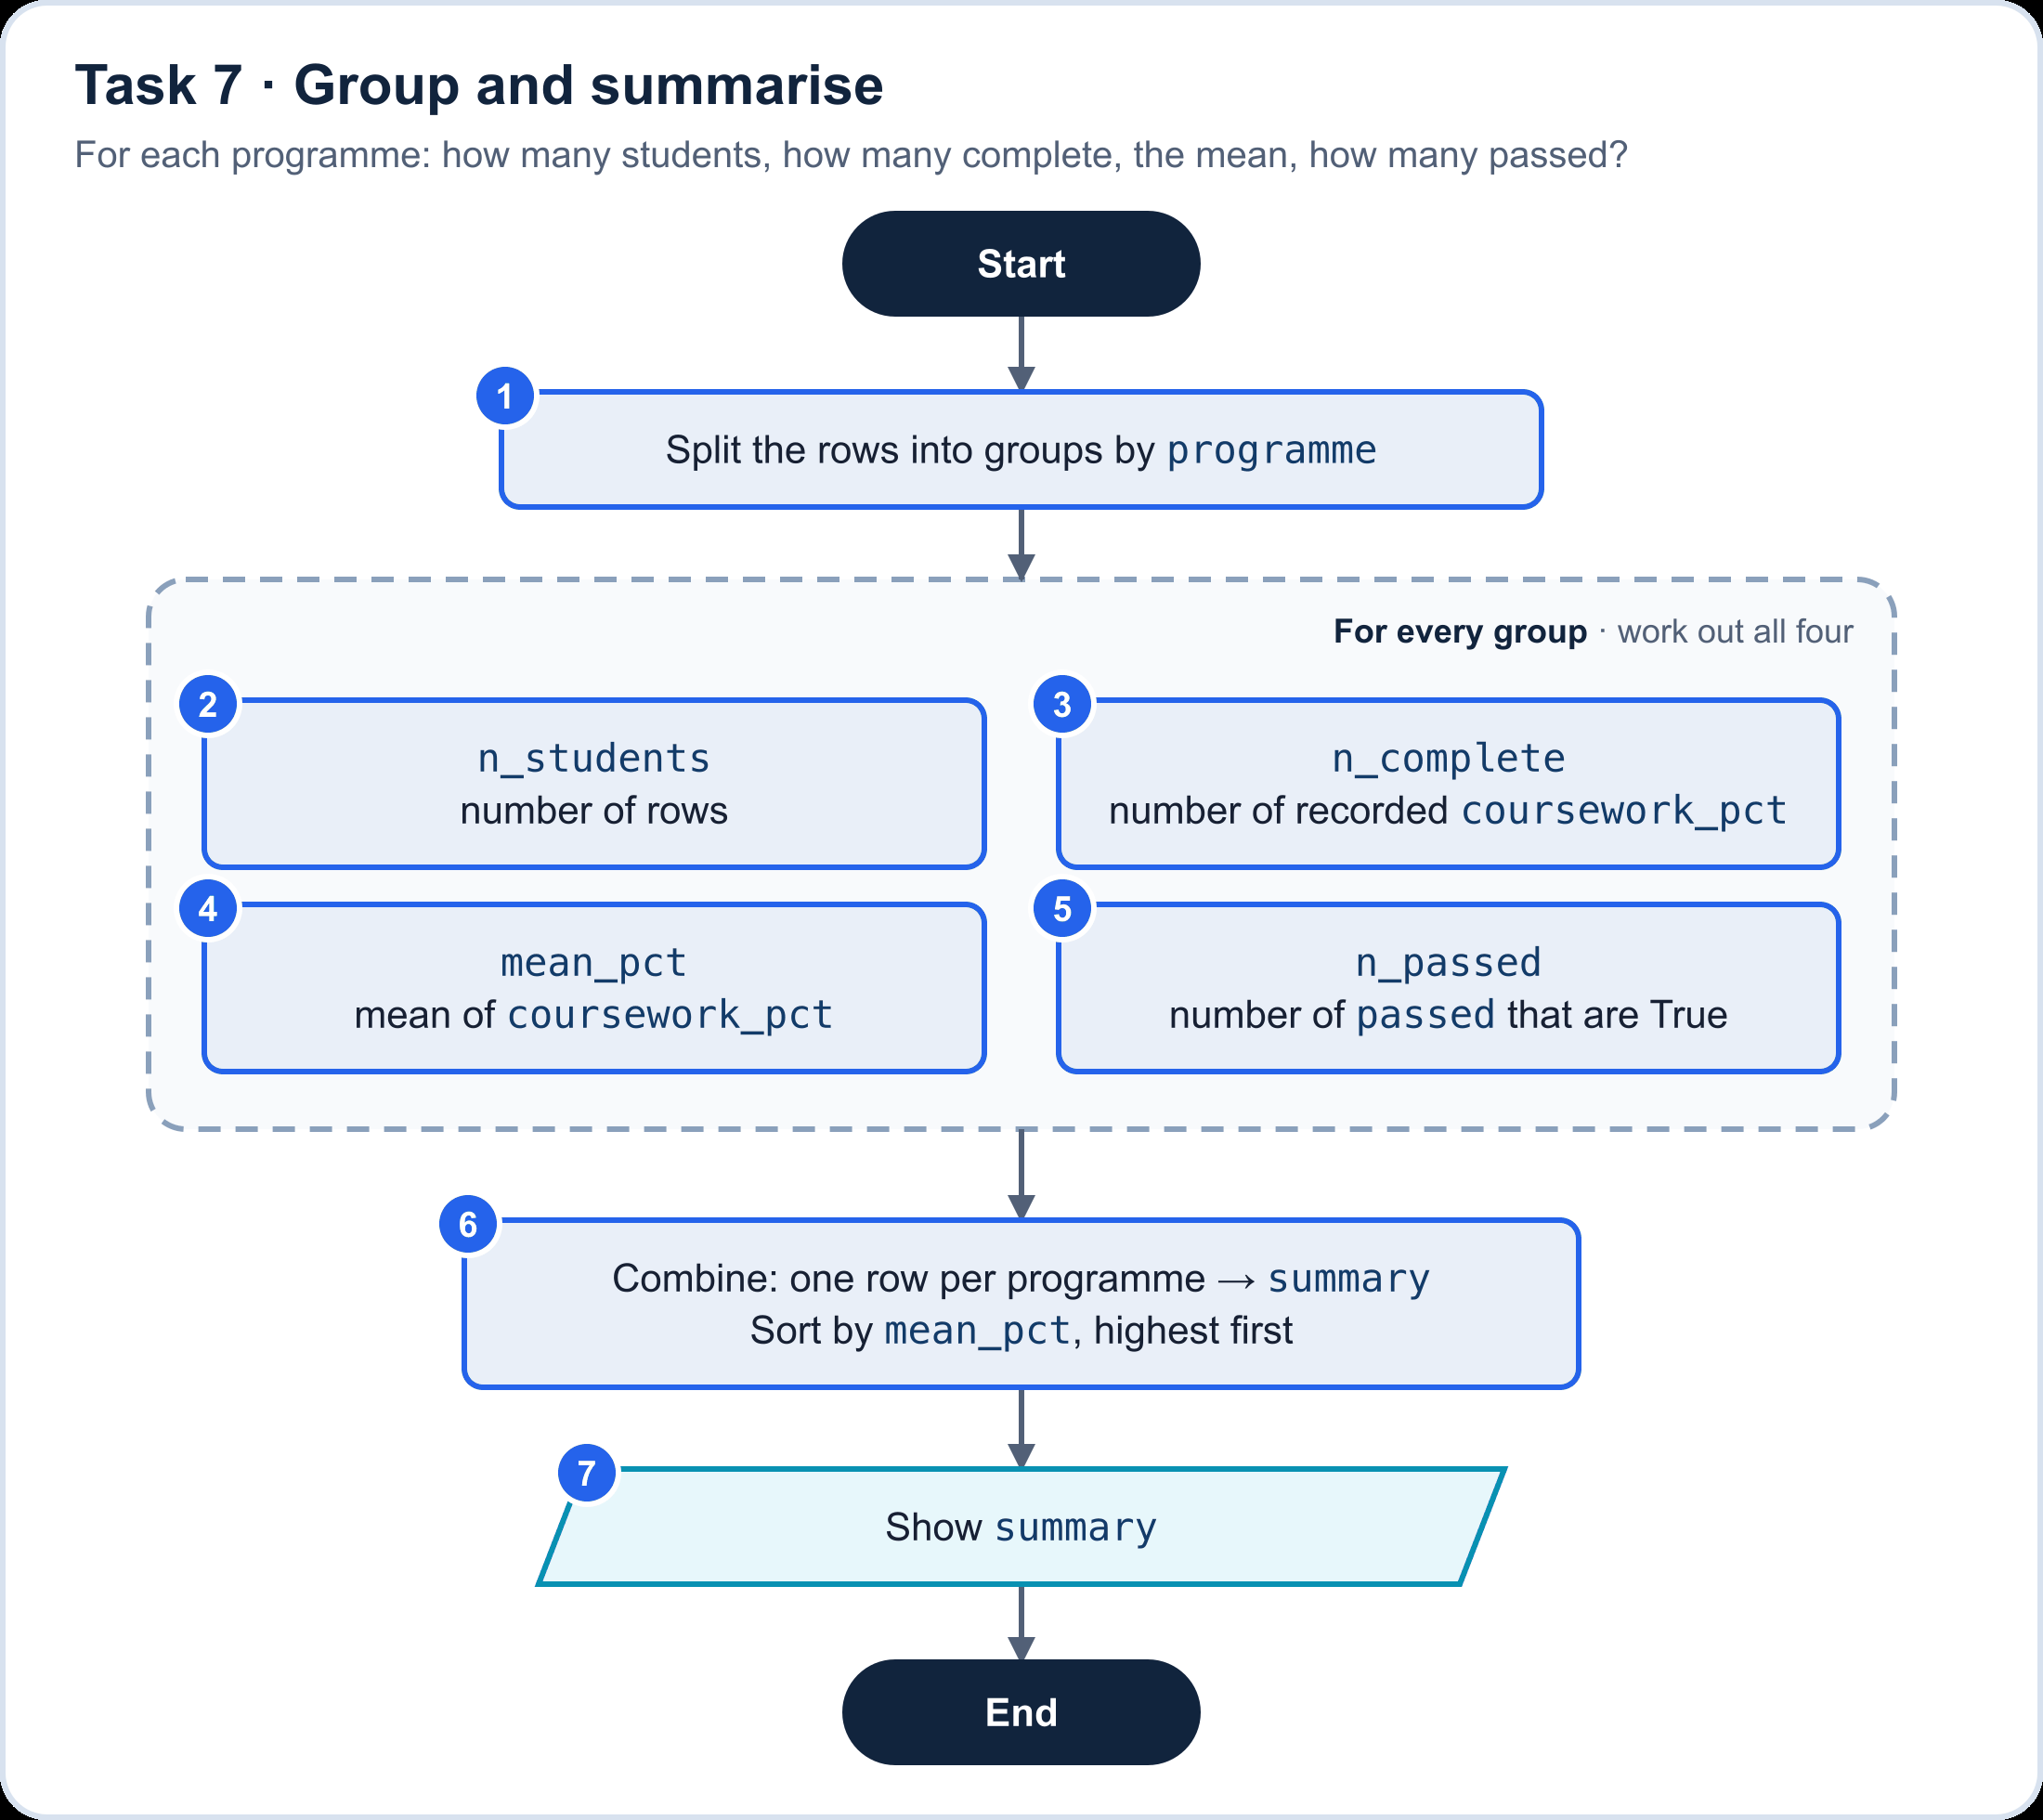

In [14]:
summary = (
    marks.groupby("programme", as_index=False)   # ①
    .agg(
        n_students=("matric", "count"),          # ②
        n_complete=("coursework_pct", "count"),  # ③
        mean_pct=("coursework_pct","mean"),    # ④
        n_passed=("passed", "sum"),            # ⑤ True counts as 1
    )
    .sort_values("mean_pct", ascending=False)       # ⑥
)

# ⑦
print(summary.round(1))

  programme  n_students  n_complete  mean_pct  n_passed
3        SE           2           1      82.0         1
0        CS           1           1      78.0         1
1        DS           3           3      72.0         2
2        IT           2           2      57.0         2


In [15]:
# Check: run this after the cell above
assert list(summary.columns) == ["programme", "n_students", "n_complete", "mean_pct", "n_passed"], "keep the column names given"
assert summary["programme"].tolist() == ["SE", "CS", "DS", "IT"], "⑥ sort by mean_pct, highest first"
assert summary["n_students"].tolist() == [2, 1, 3, 2], "② count every row in the group, missing values included"
assert summary["n_complete"].tolist() == [1, 1, 3, 2], "③ count only the recorded coursework_pct values"
assert summary["n_passed"].tolist() == [1, 1, 2, 2], "⑤ add up the True values"
print("✅ Task 7 done")

✅ Task 7 done


**✍️ Think:** SE has the highest mean. How many students is that mean based on? Write the one-sentence footnote you would put under this table.

*Your answer: The SE mean coursework percentage is based on only 1 student with a recorded coursework result, so it should be interpreted with caution. 

---
## Task 8 · Challenge: write all the code yourself

**Question:** What is the pass rate (%) of each programme, among students with complete coursework?

![Task 8 flowchart: Start; 1 keep only students with a recorded coursework_pct, giving complete; 2 left-join the programme names onto complete, many to one; 3 decision: is any student missing a programme name? Yes 4 label them Unknown programme; 5 for every programme_name count the students as n_students and the percentage of passed that are True as pass_rate; 6 sort by pass_rate highest first, then programme_name A to Z; 7 show pass_rates; End.](attachment:task8.png)

There are no blanks this time: write the code for every step. Name the final table `pass_rates` with the columns `programme_name`, `n_students` and `pass_rate`.

**Hints**

- ① `.dropna(subset=[...])` keeps the rows where the named columns are recorded.
- ② You wrote this join in Task 6.
- ③ ④ `.isna().any()` gives one True/False for a whole column; `.fillna("Unknown programme")` fills the gaps.
- ⑤ The mean of a True/False column is the proportion of `True` values. Multiply by 100 for a percentage.
- ⑥ `.sort_values(by=[first, second], ascending=[False, True])`

**Expected result**

| programme_name | n_students | pass_rate |
|---|---:|---:|
| Information Technology | 2 | 100.0 |
| Software Engineering | 1 | 100.0 |
| Unknown programme | 1 | 100.0 |
| Data Science | 3 | 66.7 |
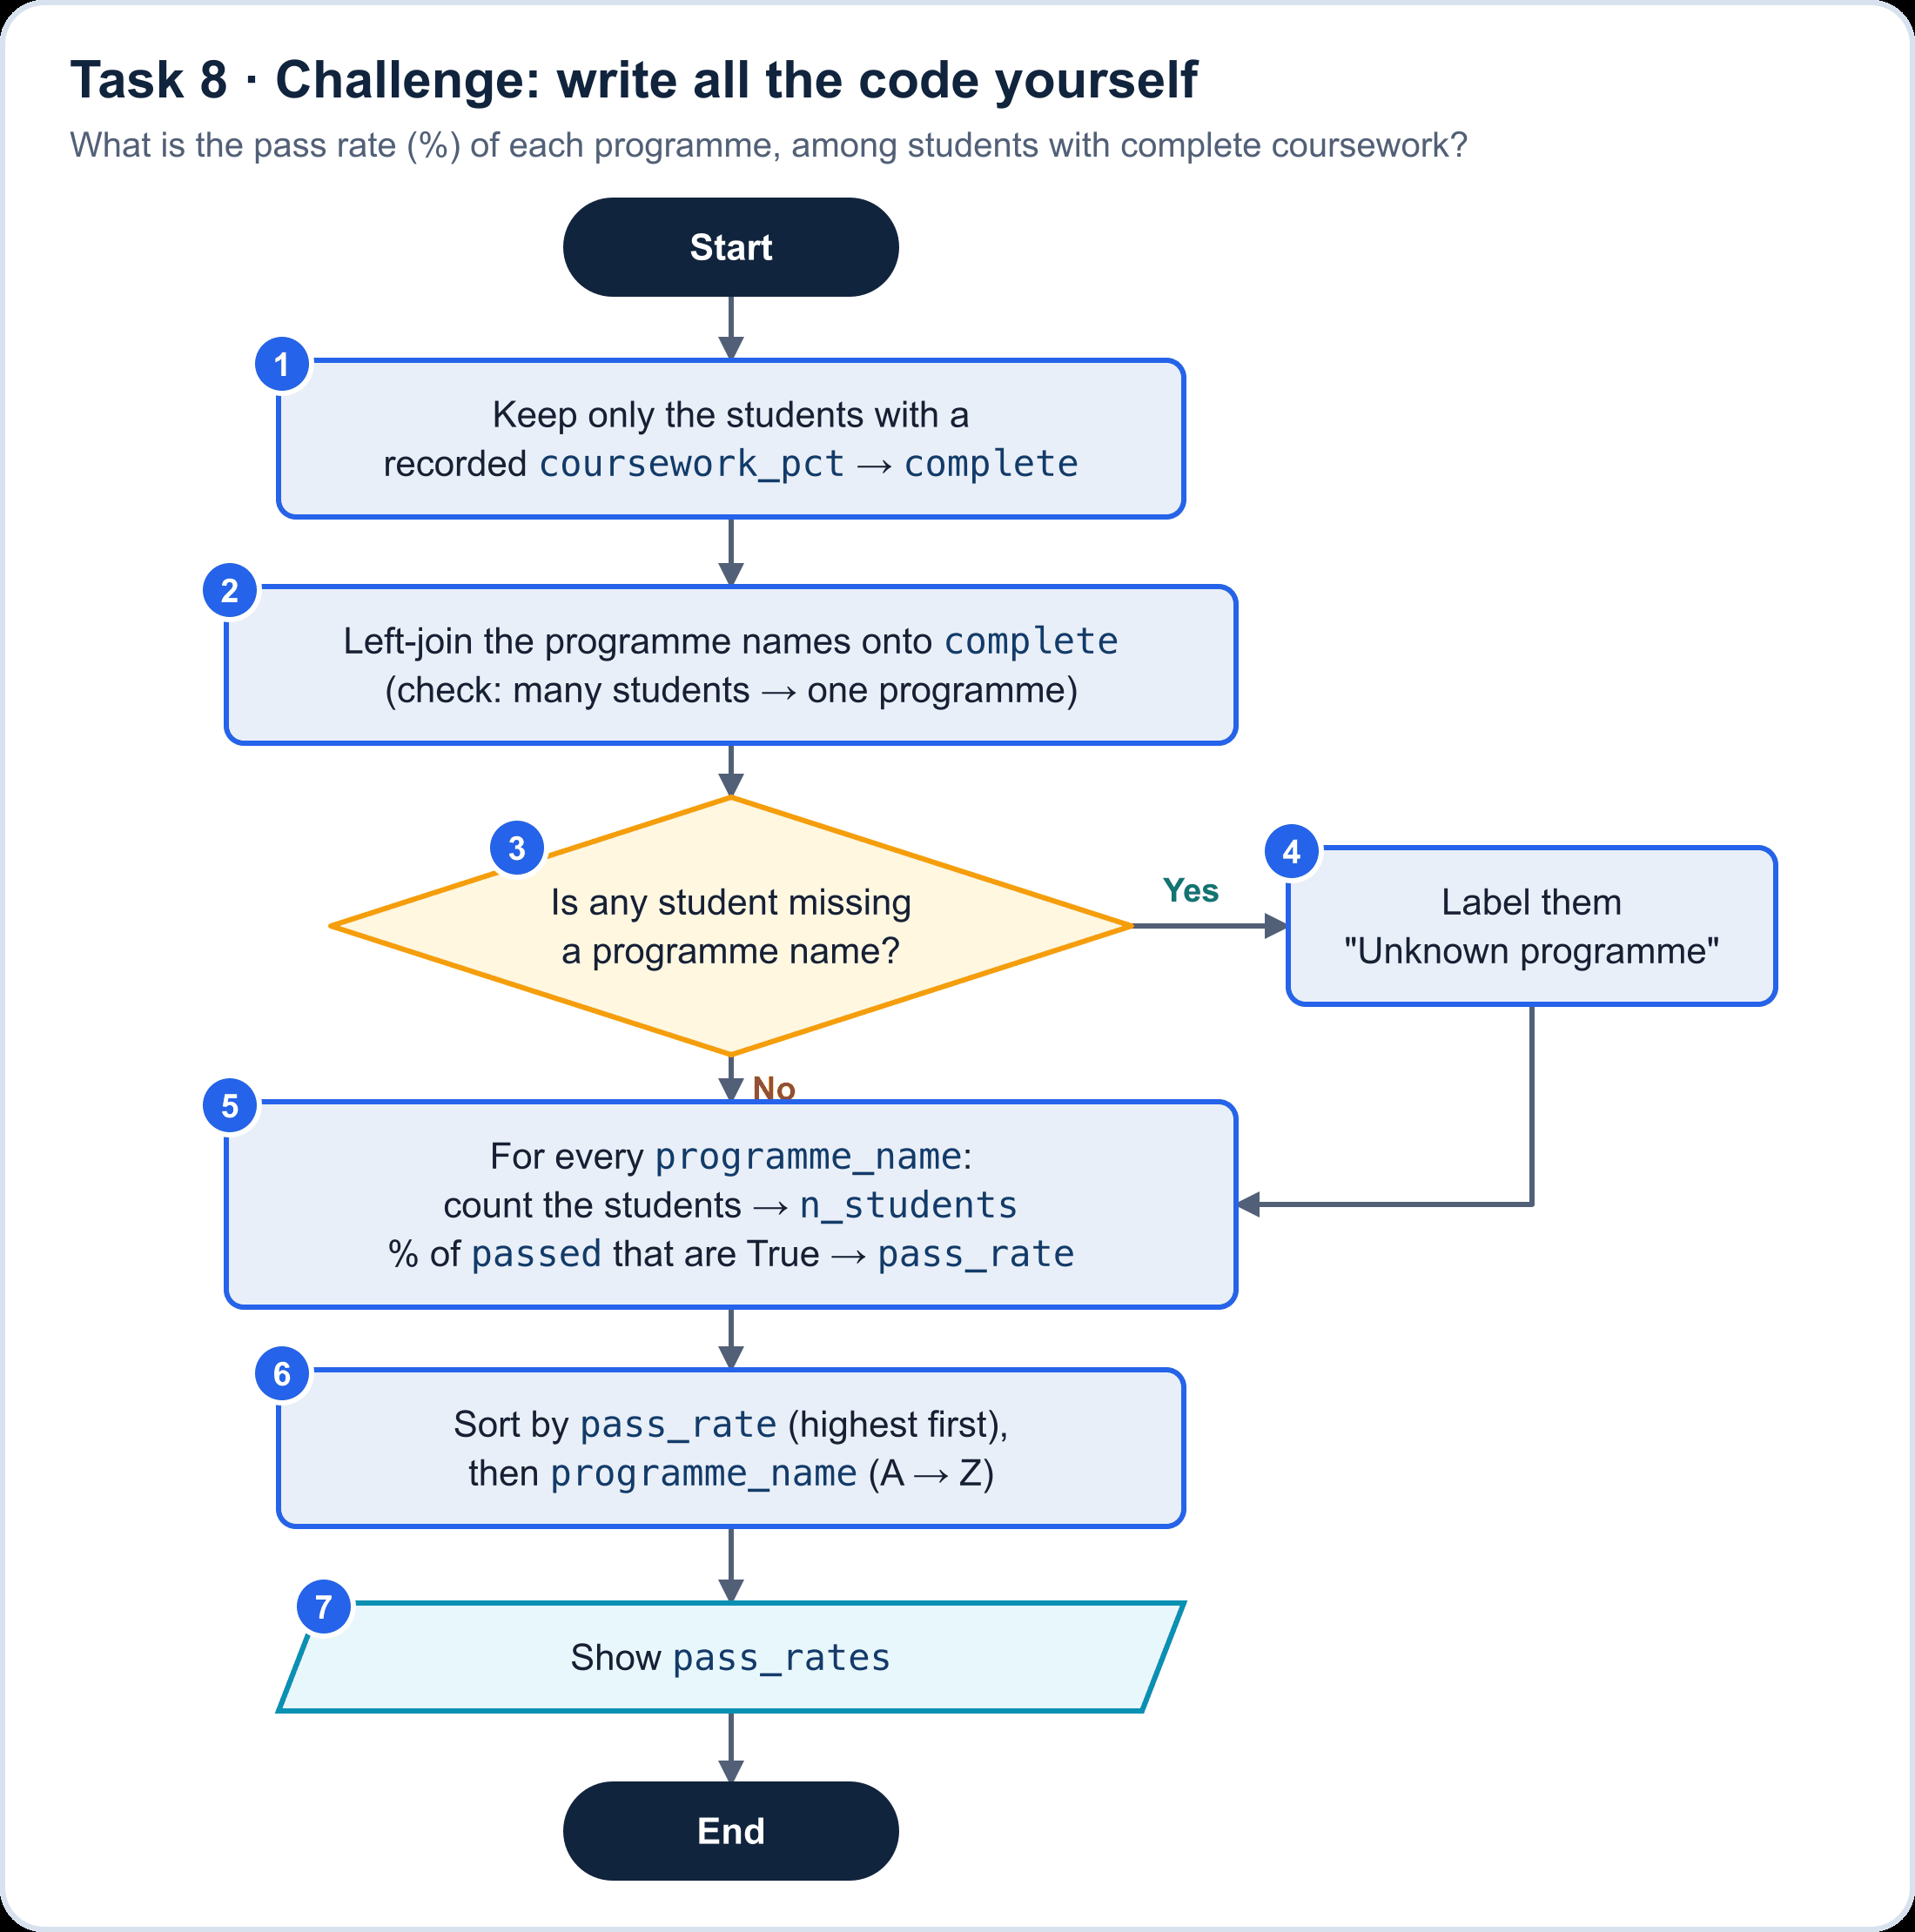

In [16]:
# ①
complete = marks.dropna(subset=["coursework_pct"])

# ②
complete = complete.merge(
    programmes,
    on="programme",
    how="left",
    validate="many_to_one"
)

# ③ ④
if complete["programme_name"].isna().any():
    complete["programme_name"] = complete["programme_name"].fillna(
        "Unknown programme"
    )

# ⑤
pass_rates = (
    complete.groupby("programme_name", as_index=False)
    .agg(
        n_students=("matric", "count"),
        pass_rate=("passed", "mean")
    )
)
pass_rates["pass_rate"] = pass_rates["pass_rate"] * 100

# ⑥
pass_rates = pass_rates.sort_values(
    by=["pass_rate", "programme_name"],
    ascending=[False, True]
)

# ⑦
print(pass_rates.round(1))

           programme_name  n_students  pass_rate
1  Information Technology           2      100.0
2    Software Engineering           1      100.0
3       Unknown programme           1      100.0
0            Data Science           3       66.7


In [17]:
# Check: run this after the cell above
assert list(pass_rates.columns) == ["programme_name", "n_students", "pass_rate"], "name the columns programme_name, n_students and pass_rate"
assert pass_rates["n_students"].sum() == 7, "① keep only the students with a recorded coursework_pct"
assert pass_rates["programme_name"].tolist() == ["Information Technology", "Software Engineering", "Unknown programme", "Data Science"], "④ is Hana labelled? ⑥ sort by pass_rate, then programme_name"
assert pass_rates["pass_rate"].round(1).tolist() == [100.0, 100.0, 100.0, 66.7], "⑤ pass_rate should be a percentage from 0 to 100"
print("✅ Task 8 done: great work!")

✅ Task 8 done: great work!


**✍️ Think:** Three programmes show 100%. Why should you be careful comparing them with Data Science's 66.7%?

*Your answer: The three programmes with 100% pass rates may have very few students, while Data Science's 66.7% may be based on more students. Therefore, we should compare the number of students in each programme before drawing conclusions.

---
## Wrap-up: what did each symbol become?

Fill in the middle column with the Python you wrote today.

| Flowchart symbol | Became in Python | Tasks |
|---|---|---|
| Diamond **inside** a *for every row* frame | Boolean mask/ Boolean mask | 2, 4 |
| Diamond **outside** any frame | if statement | 3, 6 |
| Rectangle inside a *for every row* frame | Column assignment/calculation | 4 |
| Chain of diamonds inside a function | if/elif/else statements | 5 |
| *For every group* frame | groupby() | 7 |

**Before you finish:** choose **Kernel → Restart Kernel and Run All Cells**. Every Check cell should print ✅.